# 06 - Inference-time telemetry attacks on the trained intrusion-detection models

**Project:** *When One Sensor Lies: Robust Multimodal Intrusion Detection Against Inference-Time Telemetry Manipulation in 5G Open RAN*

## 1. Research objective and threat model

**Question.** Can multimodal intrusion detection keep reliable predictions when one telemetry source (Network or Radio) is manipulated at inference time while the other stays clean?

**Scope.** No model is retrained. All 6 architectures (MLP, 1D CNN, LSTM, GRU, Residual MLP, FT-Transformer) x 3 modalities (network 29, radio 32, multimodal 61 features) x 5 saved seeds (101-505) are loaded from `Models/deep_learning/comparison/` and evaluated on the **existing test partition** of `Results/split_manifest.csv`, using the **saved** imputation, scaling and feature order.

**Threat model (synthetic).** An adversary/fault can alter the *values* of the telemetry features of one sensor (or both) *after* collection and *before* the model, without access to labels or model gradients. Perturbations are **label-independent**, defined in **standardised feature space** (z = (x - mean) / scale from the saved training statistics), reproducible (fixed seeds), and fixed *a priori* - they are not tuned on test performance. Saved test predictions are used only for exact reproduction screening, never for model, attack or threshold selection.

> **These are synthetic stress tests, not validated physical 5G attacks.** No claim is made that any perturbation is realisable on a real O-RAN/5G deployment, or that it preserves protocol/physical consistency.

**How to run (later, by you):** place this notebook in the project root (next to `05_deep_learning_comparison.ipynb`) and run *Kernel -> Restart & Run All*. It writes only to a fresh `Results/inference_time_attacks_release/` directory and refuses to run if that directory is not empty; existing `Results/inference_time_attacks/` results are never touched. Requirements: `torch>=2.0 numpy pandas scikit-learn matplotlib scipy`. Execution is pinned to CPU for strict reproduction and is feasible (about 3,300 forward evaluations of ~800 windows) but writes a large `attack_predictions.csv` (see `SAVE_ALL_SEED_PREDICTIONS` in section 3).

## 2. Project structure and checkpoint inspection

In [1]:
import sys
sys.dont_write_bytecode = True
import os, json, hashlib, platform, math, warnings, itertools, time
from pathlib import Path
import numpy as np
import pandas as pd
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import torch
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix)
from scipy.stats import spearmanr

# ---- locate project root (same rule as 05_deep_learning_comparison.ipynb) ----
ROOT = Path.cwd()
for cand in [ROOT, *ROOT.parents]:
    if (cand / "Multimodal Datasets" / "multimodal_dataset_v2.csv").exists() and (cand / "Results" / "split_manifest.csv").exists():
        ROOT = cand; break
else:
    raise FileNotFoundError("Project root not found (expects 'Multimodal Datasets/multimodal_dataset_v2.csv' and 'Results/split_manifest.csv').")

CKPT_DIR   = ROOT / "Models" / "deep_learning" / "comparison"
DLC_PATH   = CKPT_DIR / "dl_comparison_models.py"
MANIFEST_P = ROOT / "Results" / "split_manifest.csv"
DATA_P     = ROOT / "Multimodal Datasets" / "multimodal_dataset_v2.csv"
PREP_JSON  = ROOT / "Results" / "deep_learning_comparison" / "feature_names_and_preprocessing.json"
CLEAN_PRED_P = ROOT / "Results" / "deep_learning_comparison" / "test_predictions.csv"
DL_REPORT_P  = ROOT / "Results" / "deep_learning_comparison" / "deep_learning_comparison_report.md"
OUT = ROOT / "Results" / "inference_time_attacks_release"

for p in [DLC_PATH, MANIFEST_P, DATA_P, PREP_JSON, CLEAN_PRED_P, DL_REPORT_P]:
    assert p.exists(), f"missing project file: {p}"

sys.path.insert(0, str(CKPT_DIR))
import dl_comparison_models as dlc          # the project's own architectures + preprocessing + checkpoint utilities (no duplicate definitions)

# helper functions this notebook relies on (verified against the source in the project)
for fn in ["load_checkpoint", "model_from_checkpoint", "apply_preprocessing", "invert_preprocessing", "predict_proba", "build_model", "REGISTRY"]:
    assert hasattr(dlc, fn), f"dl_comparison_models.{fn} not found"

ARCHS = ["mlp", "cnn", "lstm", "gru", "resmlp", "ft_transformer"]
ARCH_LABEL = {"mlp": "MLP", "cnn": "1D CNN", "lstm": "LSTM", "gru": "GRU", "resmlp": "Residual MLP", "ft_transformer": "FT-Transformer"}
MODALITIES = ["network", "radio", "multimodal"]
SEEDS = [101, 202, 303, 404, 505]

ckpt_files = {(a, m): CKPT_DIR / f"{m}_{a}.pt" for a in ARCHS for m in MODALITIES}
missing = [str(p) for p in ckpt_files.values() if not p.exists()]
assert not missing, f"missing checkpoints: {missing}"
print("project root:", ROOT); print("checkpoints found:", len(ckpt_files), "| output folder:", OUT)

# structure of one checkpoint (as written by the export cell of notebook 05)
_c = dlc.load_checkpoint(ckpt_files[("mlp", "multimodal")])
print("checkpoint keys:", sorted(_c.keys()))
print("runs keys (seeds):", sorted(_c["runs"]), "| per-run keys:", sorted(_c["runs"][sorted(_c["runs"])[0]].keys()))
print("preprocessing keys:", sorted(_c["preprocessing"].keys()), "| model_config:", _c["model_config"], "| threshold:", _c["threshold"])
del _c

project root: <redacted local path>
checkpoints found: 18 | output folder: <redacted local path>
checkpoint keys: ['architecture', 'architecture_label', 'class_weight', 'feature_names', 'feature_order', 'feature_ranges_train_raw', 'format_version', 'frozen_record_sha256', 'input_representation', 'library_versions', 'modality', 'model_config', 'n_features', 'notes', 'positive_class', 'preprocessing', 'primary_seed', 'runs', 'seeds', 'selection_rule', 'split_manifest_sha256', 'task', 'threshold', 'training_config', 'usage']
runs keys (seeds): [101, 202, 303, 404, 505] | per-run keys: ['best_epoch', 'best_val_loss', 'epochs_run', 'state_dict', 'train_time_s']
preprocessing keys: ['feature_names', 'imputer', 'mean', 'median', 'n_train_missing_cells', 'n_train_rows', 'scale', 'scaler'] | model_config: {'hidden_dims': [256, 128, 64], 'dropout': 0.3} | threshold: 0.5


## 3. Imports and configuration

In [2]:
CONFIG = {
    "threshold": 0.5,                 # fixed decision threshold (as in notebook 05)
    "repro_tolerance": 1e-6,          # max |p_reproduced - p_saved| allowed for the clean reproduction
    "exclude_repro_failures": True,   # if True, a failing (architecture, modality, seed) is excluded from ALL attack experiments; if False, execution stops
    "eval_batch_size": 512,           # same as notebook 05
    "attack_seed": 20260,             # master seed of every perturbation (perturbations depend ONLY on it, the block and the attack spec)
    "SAVE_ALL_SEED_PREDICTIONS": True,  # True: attack_predictions.csv has all 5 seeds (~2.6M rows, several hundred MB). False: primary seed only.
    "scenario_min_windows": 1,
}
THR = CONFIG["threshold"]; ATTACK_SEED = CONFIG["attack_seed"]

DEVICE = torch.device("cpu")  # pinned to match the CPU-generated saved predictions
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True, warn_only=False)
print(f"python {platform.python_version()} | torch {torch.__version__} | device {DEVICE}")

ARCH_COLORS = {"mlp": "#4C72B0", "cnn": "#DD8452", "lstm": "#55A868", "gru": "#8172B3", "resmlp": "#937860", "ft_transformer": "#C44E52"}
# experimental conditions: (model modality, manipulated sensor(s))
CONDITIONS = [("network", "network"), ("radio", "radio"), ("multimodal", "network"), ("multimodal", "radio"), ("multimodal", "both")]
COND_LABEL = {("network", "network"): "Network model | Network manipulated", ("radio", "radio"): "Radio model | Radio manipulated",
              ("multimodal", "network"): "Multimodal | Network manipulated", ("multimodal", "radio"): "Multimodal | Radio manipulated",
              ("multimodal", "both"): "Multimodal | Both manipulated"}
if OUT.exists() and any(OUT.iterdir()):
    raise FileExistsError(f"release output directory is not empty: {OUT}; archive or remove it explicitly before rerunning")
OUT.mkdir(parents=True, exist_ok=True)

python 3.12.10 | torch 2.15.0+cpu | device cpu


## 4. Reproducibility

In [3]:
def stable_seed(*parts):
    """Deterministic 32-bit seed from arbitrary parts (independent of Python's hash randomisation)."""
    return int.from_bytes(hashlib.sha256("|".join(map(str, parts)).encode()).digest()[:8], "little") % (2 ** 32)

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

# fingerprints of every pre-existing input; re-checked in section 16 to prove nothing was modified
PROTECTED = [MANIFEST_P, DATA_P, PREP_JSON, CLEAN_PRED_P, DL_REPORT_P, DLC_PATH, *ckpt_files.values(),
             ROOT / "04_baseline_models.ipynb", ROOT / "05_deep_learning_comparison.ipynb"]
HASH_BEFORE = {str(p.relative_to(ROOT)): sha(p) for p in PROTECTED if p.exists()}
print("protected files fingerprinted:", len(HASH_BEFORE))
print("master attack seed:", ATTACK_SEED, "| all perturbations are generated from stable_seed(ATTACK_SEED, sensor block, attack family, stream)")

protected files fingerprinted: 26
master attack seed: 20260 | all perturbations are generated from stable_seed(ATTACK_SEED, sensor block, attack family, stream)


## 5. Dataset and test split loading

In [4]:
df = pd.read_csv(DATA_P); manifest = pd.read_csv(MANIFEST_P)
TARGET = "is_attack"
n_all = len(df)
split_checks = {
    "one manifest row per dataset row, in dataset order": len(manifest) == n_all and (manifest["row_index"].to_numpy() == np.arange(n_all)).all(),
    "manifest sample_id == dataset window_id": (manifest["sample_id"].to_numpy() == df["window_id"].to_numpy()).all(),
    "manifest scenario == dataset scenario": (manifest["scenario"].to_numpy() == df["scenario"].to_numpy()).all(),
    "manifest label == dataset label": (manifest["is_attack"].to_numpy() == df[TARGET].to_numpy()).all(),
    "no scenario spans two partitions": (manifest.groupby("scenario")["partition"].nunique() == 1).all(),
}
display(pd.Series(split_checks, name="passed").to_frame()); assert all(split_checks.values())

idx_test = np.flatnonzero(manifest["partition"].to_numpy() == "test")        # the EXACT existing test partition (no new split)
y_test = df[TARGET].to_numpy()[idx_test].astype(int)
# metadata kept OUT of model inputs: only used for identification and scenario-level reporting
META = pd.DataFrame({"window_id": df["window_id"].to_numpy()[idx_test], "scenario_id": df["scenario"].to_numpy()[idx_test],
                     "y_true": y_test, "row_index": idx_test})
SCEN = META["scenario_id"].to_numpy()
print(f"test windows: {len(idx_test)} | scenarios: {META.scenario_id.nunique()} | attack windows: {int(y_test.sum())} | benign windows: {int((1 - y_test).sum())}")
display(META.groupby("scenario_id").agg(windows=("y_true", "size"), is_attack=("y_true", "max")).T)

feat_json = json.load(open(PREP_JSON, encoding="utf-8"))
FEATURES = {m: list(feat_json["features_in_order"][m]) for m in MODALITIES}
N_FEATURES = {m: int(feat_json["n_features"][m]) for m in MODALITIES}
NET_N, RAD_N = N_FEATURES["network"], N_FEATURES["radio"]
assert NET_N + RAD_N == N_FEATURES["multimodal"]
assert all(len(FEATURES[m]) == N_FEATURES[m] for m in MODALITIES)
assert FEATURES["multimodal"] == FEATURES["network"] + FEATURES["radio"], "multimodal feature order must be network block + radio block"
assert all(c in df.columns for c in FEATURES["multimodal"])
FORBIDDEN = {"is_attack", "class_fm", "mode", "scenario", "window_id", "timestamp_s", "row_index", "sample_id", "partition"}
assert not (set(FEATURES["multimodal"]) & FORBIDDEN), "metadata column found in the feature list"
print(f"feature order: multimodal = network[0:{NET_N}] + radio[{NET_N}:{NET_N + RAD_N}] (from the saved JSON); no metadata column among the features")

,passed
"one manifest row per dataset row, in dataset order",True
manifest sample_id == dataset window_id,True
manifest scenario == dataset scenario,True
manifest label == dataset label,True
no scenario spans two partitions,True


test windows: 802 | scenarios: 7 | attack windows: 573 | benign windows: 229


scenario_id,Benign4,DDOSTCP1,DDOSTCP2,PortScan1,SYN2,TCP3,UDP3
windows,229,100,107,2,121,119,124
is_attack,0,1,1,1,1,1,1


feature order: multimodal = network[0:29] + radio[29:61] (from the saved JSON); no metadata column among the features


## 6. Checkpoint loading

In [5]:
CKPTS = {}
for (a, m), p in ckpt_files.items():
    ck = dlc.load_checkpoint(p)
    assert ck["architecture"] == a and ck["modality"] == m, (p, ck["architecture"], ck["modality"])
    assert list(ck["feature_names"]) == FEATURES[m], f"feature order mismatch in {p.name}"
    assert list(ck["preprocessing"]["feature_names"]) == FEATURES[m]
    assert sorted(ck["runs"]) == SEEDS, f"{p.name}: seeds {sorted(ck['runs'])}"
    assert abs(float(ck["threshold"]) - THR) < 1e-12
    CKPTS[(a, m)] = ck

# saved preprocessing must be identical across architectures for a given modality, and multimodal = network (+) radio statistics
PREP = {m: CKPTS[("mlp", m)]["preprocessing"] for m in MODALITIES}
for m in MODALITIES:
    for a in ARCHS:
        for k in ["median", "mean", "scale"]:
            assert np.array_equal(np.asarray(CKPTS[(a, m)]["preprocessing"][k]), np.asarray(PREP[m][k])), (a, m, k)
for k in ["median", "mean", "scale"]:
    assert np.allclose(np.asarray(PREP["multimodal"][k]), np.concatenate([PREP["network"][k], PREP["radio"][k]]), rtol=0, atol=1e-12), k
print("18 checkpoints loaded; feature names/order, seeds and threshold verified; saved preprocessing identical across architectures")

_MODELS = {}
def get_model(arch, modality, seed):
    """Project utility dlc.model_from_checkpoint (builds the saved architecture + loads saved weights, eval mode)."""
    key = (arch, modality, seed)
    if key not in _MODELS:
        _MODELS[key] = dlc.model_from_checkpoint(CKPTS[(arch, modality)], seed).to(DEVICE).eval()
    return _MODELS[key]

@torch.no_grad()
def predict_Z(arch, modality, seed, Z):
    """Attack probability from MODEL-SPACE input Z (n, F). Same computation as dlc.predict_proba after apply_preprocessing."""
    model = get_model(arch, modality, seed); out = []
    for i in range(0, len(Z), CONFIG["eval_batch_size"]):
        zb = torch.from_numpy(np.ascontiguousarray(Z[i:i + CONFIG["eval_batch_size"]], dtype=np.float32)).to(DEVICE)
        out.append(torch.sigmoid(model(zb).double()).cpu().numpy())
    p = np.concatenate(out)
    assert p.shape == (len(Z),) and np.isfinite(p).all(), (p.shape, len(Z))
    return p

18 checkpoints loaded; feature names/order, seeds and threshold verified; saved preprocessing identical across architectures


## 7. Clean prediction reproduction
The saved models must reproduce `Results/deep_learning_comparison/test_predictions.csv` (max |difference| <= 1e-6) before any attack is run. A failing (architecture, modality, seed) is **excluded and reported**, not silently patched.

In [6]:
# clean model-space inputs, built ONLY with the project's saved preprocessing (no new scaler / imputer is fitted)
Z_CLEAN = {m: dlc.apply_preprocessing(df.iloc[idx_test][FEATURES[m]], PREP[m]) for m in MODALITIES}
assert all(Z_CLEAN[m].shape == (len(idx_test), N_FEATURES[m]) and np.isfinite(Z_CLEAN[m]).all() for m in MODALITIES)
NET_SL, RAD_SL = slice(0, NET_N), slice(NET_N, NET_N + RAD_N)
assert np.allclose(Z_CLEAN["multimodal"][:, NET_SL], Z_CLEAN["network"], atol=1e-6) and np.allclose(Z_CLEAN["multimodal"][:, RAD_SL], Z_CLEAN["radio"], atol=1e-6)
Z_BLOCK = {"network": Z_CLEAN["network"], "radio": Z_CLEAN["radio"]}            # clean sensor blocks (identical to the multimodal slices)

saved = pd.read_csv(CLEAN_PRED_P)
saved = saved[saved["partition"] == "test"]
CLEAN_P, REPRO_ROWS = {}, []
for (a, m), s in itertools.product([(a, m) for a in ARCHS for m in MODALITIES], SEEDS):
    g = saved[(saved.architecture == a) & (saved.modality == m) & (saved.seed == s)].set_index("row_index")
    row = {"architecture": a, "modality": m, "seed": s, "n_saved": len(g), "status": "", "max_abs_diff": np.nan, "pred_flips_vs_saved": np.nan}
    try:
        assert len(g) == len(idx_test) and set(g.index) == set(idx_test), "saved predictions do not cover exactly the test partition"
        g = g.loc[idx_test]
        assert (g["window_id"].to_numpy() == META["window_id"].to_numpy()).all() and (g["y_true"].to_numpy() == y_test).all(), "window_id / label mismatch"
        p = predict_Z(a, m, s, Z_CLEAN[m]); d = np.abs(p - g["y_probability"].to_numpy())
        row["max_abs_diff"] = float(d.max()); row["pred_flips_vs_saved"] = int(((p >= THR).astype(int) != g["y_pred"].to_numpy()).sum())
        if d.max() <= CONFIG["repro_tolerance"] and row["pred_flips_vs_saved"] == 0: row["status"] = "OK"; CLEAN_P[(a, m, s)] = p
        else: row["status"] = f"FAILED: max diff {d.max():.3e} (tol {CONFIG['repro_tolerance']:.0e}), threshold flips {row['pred_flips_vs_saved']}"
    except Exception as e:
        row["status"] = f"FAILED: {type(e).__name__}: {e}"
    REPRO_ROWS.append(row)
REPRO = pd.DataFrame(REPRO_ROWS)
n_ok = int((REPRO.status == "OK").sum())
print(f"reproduction OK: {n_ok}/{len(REPRO)} | worst max |diff|: {REPRO.max_abs_diff.max():.3e}")
display(REPRO.groupby(["architecture", "modality"]).agg(ok=("status", lambda x: int((x == "OK").sum())), max_abs_diff=("max_abs_diff", "max"), max_pred_flips=("pred_flips_vs_saved", "max")).unstack("modality"))
FAILED = REPRO[REPRO.status != "OK"]
if len(FAILED):
    print("\n!!! REPRODUCTION FAILURES - these runs are EXCLUDED from all attack experiments (exact incompatibility below):")
    display(FAILED[["architecture", "modality", "seed", "status"]])
    print("Note: if the saved predictions were produced on a different device (e.g. GPU vs CPU), tiny float differences can exceed 1e-6; the tolerance is NOT relaxed automatically.")
    if not CONFIG["exclude_repro_failures"]: raise RuntimeError("exclude_repro_failures=False requested; fix reproduction first (exclusion disabled).")
RUNNABLE = sorted(CLEAN_P.keys(), key=lambda k: (ARCHS.index(k[0]), MODALITIES.index(k[1]), k[2]))
assert len(RUNNABLE) > 0, "no run reproduces the saved clean predictions - stopping."

reproduction OK: 90/90 | worst max |diff|: 0.000e+00


ok               max_abs_diff                \
modality       multimodal network radio   multimodal network radio   
architecture                                                         
cnn                     5       5     5          0.0     0.0   0.0   
ft_transformer          5       5     5          0.0     0.0   0.0   
gru                     5       5     5          0.0     0.0   0.0   
lstm                    5       5     5          0.0     0.0   0.0   
mlp                     5       5     5          0.0     0.0   0.0   
resmlp                  5       5     5          0.0     0.0   0.0   

               max_pred_flips                
modality           multimodal network radio  
architecture                                 
cnn                         0       0     0  
ft_transformer              0       0     0  
gru                         0       0     0  
lstm                        0       0     0  
mlp                         0       0     0  
resmlp                      0       0     0

## 8. Attack definitions

All transformations act on the standardised block **Z_b** (n x F_b) of a manipulated sensor *b* in {network, radio}; `z` below is one standardised value, `S` a fixed feature subset. Perturbations depend only on `(attack_seed, block, attack family)`, so **every architecture/seed sees the identical manipulated telemetry**, and nothing depends on labels, scenarios or model outputs.

| Attack | Transformation | Affected features | Severities |
|---|---|---|---|
| A. `gaussian_noise` | z' = z + sigma * eps, eps ~ N(0,1) (one fixed draw, scaled by sigma) | all features of block | sigma = 0.1, 0.25, 0.5, 1.0 |
| B. `bias_pos` / `bias_neg` | z' = z + delta on S | S = 25% of block features (fixed random subset) | delta = +0.5, +1, +2 / -0.5, -1, -2 |
| C. `scaling` | z' = c * z on S (scaling about the training mean) | S = 25% of block | c = 0.5, 2, 4 |
| D. `feature_corruption` | z' = u on S, u ~ N(0,1) iid (uninformative replacement drawn from the standardised training marginal assumption) | S = 10% / 25% / 50% of block (nested subsets) | 10%, 25%, 50% |
| E1. `sensor_dropout_partial` | z' = z_med on S, z_med = (median - mean)/scale, i.e. value missing -> **saved training median imputation** | S = 25% / 50% of block | 25%, 50% |
| E2. `sensor_dropout_complete` | same as E1 on **all** features of the block | whole sensor | 100% |
| F. `combined` | apply in order: bias (+delta on 25% subset) -> corruption (frac) -> noise (sigma) | as in A, B, D | low (0.1, +0.5, 10%), medium (0.25, +1, 25%), high (0.5, +2, 50%) |

Subsets are `sorted(permutation(F_b, rng)[:k])` with `rng = default_rng(stable_seed(attack_seed, block, family, "subset"))`; because the permutation is shared inside a family, subsets are nested across severities. No clipping is applied (standardised features have heavy tails; clean z-ranges are reported in section 9). Dropout is represented exactly as the training pipeline would see a missing value: median imputation (checked below against `dlc.apply_preprocessing` on raw NaNs).

In [7]:
FAMILY_ORDER = ["gaussian_noise", "bias_pos", "bias_neg", "scaling", "feature_corruption", "sensor_dropout_partial", "sensor_dropout_complete", "combined"]

def build_attack_grid():
    grid = []
    def add(t, sev, rank, **params):
        grid.append({"attack_id": f"{t}|{sev}", "attack_type": t, "severity": str(sev), "severity_rank": rank, "params": params})
    for i, s in enumerate([0.1, 0.25, 0.5, 1.0]): add("gaussian_noise", s, i, sigma=s)
    for i, d in enumerate([0.5, 1.0, 2.0]): add("bias_pos", f"+{d:g}", i, delta=d, frac=0.25)
    for i, d in enumerate([0.5, 1.0, 2.0]): add("bias_neg", f"-{d:g}", i, delta=-d, frac=0.25)
    for i, c in enumerate([0.5, 2.0, 4.0]): add("scaling", f"x{c:g}", i, factor=c, frac=0.25)
    for i, f in enumerate([0.10, 0.25, 0.50]): add("feature_corruption", f"{int(f * 100)}%", i, frac=f)
    for i, f in enumerate([0.25, 0.50]): add("sensor_dropout_partial", f"{int(f * 100)}%", i, frac=f)
    add("sensor_dropout_complete", "100%", 0, frac=1.0)
    for i, (n, sg, d, f) in enumerate([("low", 0.1, 0.5, 0.10), ("medium", 0.25, 1.0, 0.25), ("high", 0.5, 2.0, 0.50)]):
        add("combined", n, i, sigma=sg, delta=d, bias_frac=0.25, corr_frac=f)
    return grid

ATTACK_GRID = build_attack_grid()
ATTACK_BY_ID = {a["attack_id"]: a for a in ATTACK_GRID}
assert len(ATTACK_GRID) == 22 and len(ATTACK_BY_ID) == 22
Z_MEDIAN = {b: (np.asarray(PREP[b]["median"]) - np.asarray(PREP[b]["mean"])) / np.asarray(PREP[b]["scale"]) for b in ["network", "radio"]}

def feature_subset(block, family, F, frac):
    perm = np.random.default_rng(stable_seed(ATTACK_SEED, block, family, "subset")).permutation(F)
    return np.sort(perm[:max(1, int(round(frac * F)))])

def perturb_block(Zb, spec, block):
    """Apply one attack spec to the clean standardised block Zb (n, F_b). Returns (perturbed copy, sorted affected feature indices)."""
    t, p = spec["attack_type"], spec["params"]; assert Zb.ndim == 2 and np.isfinite(Zb).all(); F = Zb.shape[1]; Z = Zb.astype(np.float64).copy()
    noise = lambda: np.random.default_rng(stable_seed(ATTACK_SEED, block, "noise", "eps")).standard_normal(Zb.shape)
    corr_vals = lambda: np.random.default_rng(stable_seed(ATTACK_SEED, block, "corruption", "values")).standard_normal(Zb.shape)
    if t == "gaussian_noise":
        Z += p["sigma"] * noise(); aff = np.arange(F)
    elif t in ("bias_pos", "bias_neg"):
        aff = feature_subset(block, "bias", F, p["frac"]); Z[:, aff] += p["delta"]
    elif t == "scaling":
        aff = feature_subset(block, "scaling", F, p["frac"]); Z[:, aff] *= p["factor"]
    elif t == "feature_corruption":
        aff = feature_subset(block, "corruption", F, p["frac"]); Z[:, aff] = corr_vals()[:, aff]
    elif t in ("sensor_dropout_partial", "sensor_dropout_complete"):
        aff = np.arange(F) if t == "sensor_dropout_complete" else feature_subset(block, "dropout", F, p["frac"])
        Z[:, aff] = Z_MEDIAN[block][aff]
    elif t == "combined":
        ab = feature_subset(block, "bias", F, p["bias_frac"]); Z[:, ab] += p["delta"]
        ac = feature_subset(block, "corruption", F, p["corr_frac"]); Z[:, ac] = corr_vals()[:, ac]
        Z += p["sigma"] * noise(); aff = np.arange(F)
    else:
        raise ValueError(t)
    Z = Z.astype(np.float32); aff = np.asarray(aff, dtype=int)
    assert Z.shape == Zb.shape and np.isfinite(Z).all(), (spec["attack_id"], Z.shape, Zb.shape)
    assert aff.ndim == 1 and np.array_equal(aff, np.sort(aff)) and np.unique(aff).size == aff.size and ((aff >= 0) & (aff < F)).all(), aff
    return Z, aff

# --- self-checks of the perturbation code (no model involved) ---
_spec = ATTACK_BY_ID["gaussian_noise|0.5"]
_a, _ = perturb_block(Z_BLOCK["network"], _spec, "network"); _b, _ = perturb_block(Z_BLOCK["network"], _spec, "network")
assert np.array_equal(_a, _b), "perturbations must be deterministic"
_sd = float(np.std(_a.astype(np.float64) - Z_BLOCK["network"])); assert abs(_sd - 0.5) < 0.05, _sd
_raw = df.iloc[idx_test][FEATURES["radio"]].head(8).copy(); _aff = feature_subset("radio", "dropout", RAD_N, 0.5)
_raw = _raw.astype(np.float64)  # allow NaN in raw integer telemetry columns
_raw.iloc[:, _aff] = np.nan  # missing value as the saved pipeline would see it
_ref = dlc.apply_preprocessing(_raw, PREP["radio"]); _got, _ = perturb_block(Z_BLOCK["radio"][:8], ATTACK_BY_ID["sensor_dropout_partial|50%"], "radio")
assert np.allclose(_ref, _got, atol=1e-5), "dropout representation must equal the saved median imputation"
assert _got.shape == Z_BLOCK["radio"][:8].shape and np.isfinite(_got).all()
print("perturbation self-checks passed: determinism, noise scale, dropout == saved median imputation (verified against dlc.apply_preprocessing)")

perturbation self-checks passed: determinism, noise scale, dropout == saved median imputation (verified against dlc.apply_preprocessing)


## 9. Attack generation
Perturbed sensor blocks are generated once per (sensor, attack) and shared by all architectures and seeds. The attack configuration (formula, seed, affected features, severity) is exported to `attack_configuration.json`.

In [8]:
PERT = {}
def get_pert(block, attack_id):
    key = (block, attack_id)
    if key not in PERT: PERT[key] = perturb_block(Z_BLOCK[block], ATTACK_BY_ID[attack_id], block)
    return PERT[key]

TARGET_BLOCKS = {"network": ["network"], "radio": ["radio"], "both": ["network", "radio"]}
BLOCK_SLICE = {"network": {"network": slice(0, NET_N)}, "radio": {"radio": slice(0, RAD_N)}, "multimodal": {"network": NET_SL, "radio": RAD_SL}}

def attacked_input(modality, target, attack_id):
    """Model-space input where ONLY the targeted sensor block(s) are manipulated; the other block stays bit-identical to clean."""
    Z = Z_CLEAN[modality].copy()
    for b in TARGET_BLOCKS[target]:
        Z[:, BLOCK_SLICE[modality][b]] = get_pert(b, attack_id)[0]
    assert Z.shape == Z_CLEAN[modality].shape and np.isfinite(Z).all(), (modality, target, attack_id)
    return Z

def valid_targets(modality):
    return {"network": ["network"], "radio": ["radio"], "multimodal": ["network", "radio", "both"]}[modality]

# boundary self-test on the multimodal input: untargeted block unchanged, targeted block changed
_Zn = attacked_input("multimodal", "network", "gaussian_noise|0.5"); _Zr = attacked_input("multimodal", "radio", "gaussian_noise|0.5")
assert np.array_equal(_Zn[:, RAD_SL], Z_CLEAN["multimodal"][:, RAD_SL]) and not np.array_equal(_Zn[:, NET_SL], Z_CLEAN["multimodal"][:, NET_SL])
assert np.array_equal(_Zr[:, NET_SL], Z_CLEAN["multimodal"][:, NET_SL]) and not np.array_equal(_Zr[:, RAD_SL], Z_CLEAN["multimodal"][:, RAD_SL])

ATTACK_CONFIG = {
    "run_status": "in_progress",
    "disclaimer": "Synthetic, label-independent inference-time stress tests in standardised feature space. NOT validated physical 5G/O-RAN attacks.",
    "attack_seed": ATTACK_SEED, "threshold": THR, "space": "standardised features z=(x-mean)/scale using the saved training statistics",
    "feature_blocks": {"network": FEATURES["network"], "radio": FEATURES["radio"], "multimodal_boundary": {"network": [0, NET_N], "radio": [NET_N, NET_N + RAD_N]}},
    "random_streams": "numpy default_rng(stable_seed(attack_seed, block, family, stream)); stable_seed = first 8 bytes of sha256 of the joined parts mod 2^32",
    "combined_order": "bias -> feature corruption -> additive Gaussian noise",
    "attacks": [],
}
for spec in ATTACK_GRID:
    entry = {"attack_id": spec["attack_id"], "attack_type": spec["attack_type"], "severity": spec["severity"], "severity_rank": spec["severity_rank"], "params": spec["params"], "affected_features": {}}
    for b in ["network", "radio"]:
        aff = get_pert(b, spec["attack_id"])[1]
        entry["affected_features"][b] = {"n": int(len(aff)), "indices_within_block": [int(i) for i in aff], "names": [FEATURES[b][i] for i in aff]}
    ATTACK_CONFIG["attacks"].append(entry)
ATTACK_CONFIG["targets"] = {"network_model": ["network"], "radio_model": ["radio"], "multimodal_model": ["network", "radio", "both"]}
with open(OUT / "attack_configuration.json", "w", encoding="utf-8") as f: json.dump(ATTACK_CONFIG, f, indent=2)

rng_tbl = pd.DataFrame({b: {"clean max |z|": float(np.abs(Z_BLOCK[b]).max()), "clean 99th pct |z|": float(np.percentile(np.abs(Z_BLOCK[b]), 99))} for b in Z_BLOCK}).T
display(rng_tbl)
print(f"{len(ATTACK_GRID)} attack configurations x targets -> network 22 + radio 22 + multimodal 66 = 110 conditions per (architecture, seed)")

,clean max |z|,clean 99th pct |z|
network,34.314980,3.909096
radio,7.586481,2.713950


22 attack configurations x targets -> network 22 + radio 22 + multimodal 66 = 110 conditions per (architecture, seed)


## 13a. Metrics and aggregation helpers (defined before the experiments that use them)
**ESR** (Evasion Success Rate) for one (model, attack): the denominator is the set D of test windows with `y_true = 1` **and** a *clean* prediction of attack (`p_clean >= 0.5`); ESR = |{i in D : p_attacked < 0.5}| / |D|. It is **undefined (NaN)** when |D| = 0. Flip rate = share of all windows whose thresholded prediction changes; mean probability change = mean(p_attacked - p_clean) (signed), also reported separately for attack and benign windows.

In [9]:
def safe_div(a, b): return a / b if b else float("nan")

def clf_metrics(y, p, thr=THR):
    y = np.asarray(y); p = np.asarray(p, dtype=float)
    assert y.ndim == 1 and p.ndim == 1 and len(y) == len(p) and np.isfinite(p).all() and set(np.unique(y)).issubset({0, 1}), (y.shape, p.shape)
    y = y.astype(int); pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, pos_label=1, zero_division=0),
            "recall": recall_score(y, pred, pos_label=1, zero_division=0), "f1": f1_score(y, pred, pos_label=1, zero_division=0),
            "macro_f1": f1_score(y, pred, average="macro", labels=[0, 1], zero_division=0),
            "roc_auc": roc_auc_score(y, p) if both else float("nan"), "pr_auc": average_precision_score(y, p) if both else float("nan"),
            "fpr": safe_div(fp, fp + tn), "fnr": safe_div(fn, fn + tp), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def shift_metrics(y, p_clean, p_att, thr=THR):
    y = np.asarray(y); p_clean = np.asarray(p_clean, dtype=float); p_att = np.asarray(p_att, dtype=float)
    assert y.ndim == 1 and p_clean.ndim == 1 and p_att.ndim == 1 and len(y) == len(p_clean) == len(p_att)
    assert np.isfinite(p_clean).all() and np.isfinite(p_att).all() and set(np.unique(y)).issubset({0, 1})
    y = y.astype(int); cp = (p_clean >= thr).astype(int); ap = (p_att >= thr).astype(int); d = p_att - p_clean
    det = (y == 1) & (cp == 1); n_det = int(det.sum()); n_ev = int((det & (ap == 0)).sum())
    return {"flip_rate": float((cp != ap).mean()), "mean_prob_change": float(d.mean()),
            "mean_prob_change_attack": float(d[y == 1].mean()) if (y == 1).any() else float("nan"),
            "mean_prob_change_benign": float(d[y == 0].mean()) if (y == 0).any() else float("nan"),
            "mean_abs_prob_change": float(np.abs(d).mean()), "esr_numerator": n_ev, "esr_denominator": n_det, "esr": safe_div(n_ev, n_det)}

SCEN_LIST = sorted(META.scenario_id.unique())
SCEN_IDX = {s: np.flatnonzero(SCEN == s) for s in SCEN_LIST}
def scenario_rows(base, y, p_clean, p_att, thr=THR):
    rows = []
    for s, ix in SCEN_IDX.items():
        yy, pc, pa = y[ix], p_clean[ix], p_att[ix]; cp, ap = (pc >= thr).astype(int), (pa >= thr).astype(int)
        det = (yy == 1) & (cp == 1); nd = int(det.sum()); ne = int((det & (ap == 0)).sum())
        rows.append({**base, "scenario_id": s, "class": "attack" if yy.max() == 1 else "benign", "n_windows": len(ix),
                     "clean_accuracy": float((cp == yy).mean()), "attacked_accuracy": float((ap == yy).mean()),
                     "clean_mean_prob": float(pc.mean()), "attacked_mean_prob": float(pa.mean()), "mean_prob_change": float((pa - pc).mean()),
                     "flip_rate": float((cp != ap).mean()), "esr_numerator": ne, "esr_denominator": nd, "esr": safe_div(ne, nd)})
    return rows

PRED_COLS = ["window_id", "scenario_id", "y_true", "clean_probability", "attacked_probability", "clean_prediction", "attacked_prediction",
             "architecture", "modality", "seed", "attack_type", "attack_target", "severity"]
PRED_PATH = OUT / "attack_predictions.csv"
assert not PRED_PATH.exists(), f"refusing to overwrite existing predictions: {PRED_PATH}"
_pred_header = [True]
PRIMARY_SEED = {(a, m): CKPTS[(a, m)]["primary_seed"] for a in ARCHS for m in MODALITIES}

def write_predictions(a, m, s, target, spec, pc, pa):
    if not CONFIG["SAVE_ALL_SEED_PREDICTIONS"] and s != PRIMARY_SEED[(a, m)]: return 0
    fr = pd.DataFrame({"window_id": META["window_id"].to_numpy(), "scenario_id": SCEN, "y_true": y_test, "clean_probability": pc, "attacked_probability": pa,
                       "clean_prediction": (pc >= THR).astype(np.int8), "attacked_prediction": (pa >= THR).astype(np.int8),
                       "architecture": a, "modality": m, "seed": s, "attack_type": spec["attack_type"], "attack_target": target, "severity": spec["severity"]})[PRED_COLS]
    fr.to_csv(PRED_PATH, mode="a", header=_pred_header[0], index=False, float_format="%.7g"); _pred_header[0] = False
    return len(fr)

RESULT_ROWS, SCEN_ROWS, N_PRED_ROWS = [], [], [0]
def run_condition(modality, target):
    """Evaluate every reproducible (architecture, seed) of `modality` under every attack on sensor(s) `target`. Returns #evaluations."""
    assert target in valid_targets(modality)
    n_eval = 0
    for attack in ATTACK_GRID:
        Zatt = attacked_input(modality, target, attack["attack_id"])
        assert Zatt.ndim == 2 and Zatt.shape == Z_CLEAN[modality].shape and np.isfinite(Zatt).all(), (modality, target, attack["attack_id"])
        for (a, m, s) in RUNNABLE:
            if m != modality: continue
            pc = CLEAN_P[(a, m, s)]; pa = predict_Z(a, m, s, Zatt)
            base = {"architecture": a, "modality": m, "seed": s, "attack_type": attack["attack_type"], "attack_target": target,
                    "severity": attack["severity"], "severity_rank": attack["severity_rank"], "attack_id": attack["attack_id"]}
            RESULT_ROWS.append({**base, "n_test": len(y_test), **clf_metrics(y_test, pa), **shift_metrics(y_test, pc, pa)})
            SCEN_ROWS.extend(scenario_rows(base, y_test, pc, pa))
            N_PRED_ROWS[0] += write_predictions(a, m, s, target, attack, pc, pa); n_eval += 1
    return n_eval

## 10. Network experiments
Network-only models; the Network telemetry is manipulated.

In [10]:
t0 = time.perf_counter(); n = run_condition("network", "network")
print(f"network model | network manipulated: {n} evaluations in {time.perf_counter() - t0:.0f}s")

network model | network manipulated: 660 evaluations in 38s


## 11. Radio experiments
Radio-only models; the Radio telemetry is manipulated.

In [11]:
t0 = time.perf_counter(); n = run_condition("radio", "radio")
print(f"radio model | radio manipulated: {n} evaluations in {time.perf_counter() - t0:.0f}s")

radio model | radio manipulated: 660 evaluations in 39s


## 12. Multimodal sensor-specific experiments (central experiment)
For every multimodal model the four sensor states are evaluated: **clean/clean** (section 13 baseline), **Network manipulated + Radio clean**, **Network clean + Radio manipulated**, **both manipulated**. The 29/32 feature boundary is preserved exactly (`attacked_input` replaces only the targeted slice).

In [12]:
t0 = time.perf_counter()
for tgt in ["network", "radio", "both"]:
    n = run_condition("multimodal", tgt); print(f"multimodal | {tgt} manipulated: {n} evaluations ({time.perf_counter() - t0:.0f}s elapsed)")

multimodal | network manipulated: 660 evaluations (63s elapsed)
multimodal | radio manipulated: 660 evaluations (132s elapsed)
multimodal | both manipulated: 660 evaluations (194s elapsed)


## 13. Metrics and aggregation
Per-seed tables, mean +/- standard deviation over the 5 seeds (sample std, ddof=1; NaN if fewer than 2 defined values), and the robustness ranking. ESR is averaged over seeds where it is defined; `esr_n_defined` records how many.

In [13]:
assert len(RESULT_ROWS) > 0
# ---- clean baseline (reproduced predictions, verified in section 7) ----
CLEAN_DF = pd.DataFrame([{"architecture": a, "modality": m, "seed": s, "n_test": len(y_test), **clf_metrics(y_test, CLEAN_P[(a, m, s)])} for (a, m, s) in RUNNABLE])
CLEAN_DF.to_csv(OUT / "clean_baseline_metrics.csv", index=False)

# ---- per-seed attack results ----
PER_SEED = pd.DataFrame(RESULT_ROWS)
PER_SEED["cond"] = PER_SEED["modality"] + ":" + PER_SEED["attack_target"]
clean_ref = CLEAN_DF.set_index(["architecture", "modality", "seed"])[["accuracy", "macro_f1", "recall", "precision", "fpr", "fnr", "roc_auc", "pr_auc"]].add_prefix("clean_")
PER_SEED = PER_SEED.join(clean_ref, on=["architecture", "modality", "seed"])
for k in ["macro_f1", "recall", "fpr", "fnr", "accuracy", "roc_auc", "pr_auc"]:
    PER_SEED[f"delta_{k}"] = PER_SEED[k] - PER_SEED[f"clean_{k}"]
PER_SEED.to_csv(OUT / "attack_results_per_seed.csv", index=False)

# ---- summary: mean +/- std over seeds per (architecture, modality, target, attack, severity) ----
KEYS = ["architecture", "modality", "attack_target", "attack_type", "severity", "severity_rank", "attack_id"]
SUM_METRICS = ["accuracy", "precision", "recall", "f1", "macro_f1", "roc_auc", "pr_auc", "fpr", "fnr", "flip_rate", "mean_prob_change",
               "mean_prob_change_attack", "mean_prob_change_benign", "esr", "delta_macro_f1", "delta_recall", "delta_fpr", "delta_fnr", "tn", "fp", "fn", "tp"]
g = PER_SEED.groupby(KEYS, sort=False)
SUMMARY = g[SUM_METRICS].mean().add_suffix("_mean").join(g[SUM_METRICS].std(ddof=1).add_suffix("_std"))
SUMMARY["n_seeds"] = g.size(); SUMMARY["esr_n_defined"] = g["esr"].count()
SUMMARY["esr_denominator_mean"] = g["esr_denominator"].mean()
SUMMARY = SUMMARY.reset_index(); SUMMARY.to_csv(OUT / "attack_results_summary.csv", index=False)

# ---- scenario-level results ----
SCEN_DF = pd.DataFrame(SCEN_ROWS); SCEN_DF.to_csv(OUT / "scenario_level_attack_results.csv", index=False)

# ---- condition-level tables: mean over ALL attack configurations, computed per seed first ----
COND_SEED = (PER_SEED.groupby(["architecture", "modality", "attack_target", "cond", "seed"])
             .agg(macro_f1=("macro_f1", "mean"), worst_macro_f1=("macro_f1", "min"), recall=("recall", "mean"), fpr=("fpr", "mean"), fnr=("fnr", "mean"),
                  accuracy=("accuracy", "mean"), flip_rate=("flip_rate", "mean"), esr=("esr", "mean"), delta_macro_f1=("delta_macro_f1", "mean")).reset_index())
COND_SEED = COND_SEED.join(CLEAN_DF.set_index(["architecture", "modality", "seed"])[["macro_f1", "recall", "fpr", "fnr", "accuracy"]].add_prefix("clean_"), on=["architecture", "modality", "seed"])
def cond_stats(metric):
    t = COND_SEED.groupby(["architecture", "cond"])[metric].agg(["mean", "std"]).reset_index(); return t

# ---- robustness ranking (descriptive; ranking != certification of robustness) ----
rk = []
for (a, cond), d in COND_SEED.groupby(["architecture", "cond"]):
    rk.append({"architecture": a, "condition": cond, "n_seeds": len(d), "clean_macro_f1_mean": d.clean_macro_f1.mean(),
               "attacked_macro_f1_mean": d.macro_f1.mean(), "attacked_macro_f1_std_over_seeds": d.macro_f1.std(ddof=1),
               "worst_case_macro_f1_mean": d.worst_macro_f1.mean(), "mean_delta_macro_f1": d.delta_macro_f1.mean(),
               "attacked_recall_mean": d.recall.mean(), "clean_recall_mean": d.clean_recall.mean(), "attacked_fpr_mean": d.fpr.mean(), "attacked_fnr_mean": d.fnr.mean(),
               "mean_flip_rate": d.flip_rate.mean(), "mean_esr": d.esr.mean(), "esr_n_seeds_defined": int(d.esr.count())})
RANKING = pd.DataFrame(rk)
RANKING["rank_attacked_macro_f1"] = RANKING.groupby("condition")["attacked_macro_f1_mean"].rank(ascending=False, method="min")
RANKING["rank_attacked_recall"] = RANKING.groupby("condition")["attacked_recall_mean"].rank(ascending=False, method="min")
RANKING["rank_smallest_drop"] = RANKING.groupby("condition")["mean_delta_macro_f1"].rank(ascending=False, method="min")
RANKING["rank_lowest_esr"] = RANKING.groupby("condition")["mean_esr"].rank(ascending=True, method="min")
RANKING = RANKING.sort_values(["condition", "rank_attacked_macro_f1", "architecture"]); RANKING.to_csv(OUT / "robustness_ranking.csv", index=False)

print(f"per-seed rows: {len(PER_SEED):,} | summary rows: {len(SUMMARY):,} | scenario rows: {len(SCEN_DF):,} | prediction rows written: {N_PRED_ROWS[0]:,}")
display(RANKING[["architecture", "condition", "clean_macro_f1_mean", "attacked_macro_f1_mean", "attacked_macro_f1_std_over_seeds", "mean_delta_macro_f1", "attacked_recall_mean", "mean_esr", "rank_attacked_macro_f1"]].round(4))

per-seed rows: 3,300 | summary rows: 660 | scenario rows: 23,100 | prediction rows written: 2,646,600


,architecture,condition,clean_macro_f1_mean,attacked_macro_f1_mean,attacked_macro_f1_std_over_seeds,mean_delta_macro_f1,attacked_recall_mean,mean_esr,rank_attacked_macro_f1
25,resmlp,multimodal:both,0.9985,0.9455,0.0023,-0.0530,0.9792,0.0199,1.0
20,mlp,multimodal:both,0.9988,0.9394,0.0058,-0.0594,0.9710,0.0282,2.0
5,ft_transformer,multimodal:both,0.9997,0.9184,0.0071,-0.0813,0.9691,0.0308,3.0
15,lstm,multimodal:both,0.9937,0.8825,0.0303,-0.1112,0.9643,0.0323,4.0
10,gru,multimodal:both,0.9917,0.8685,0.0552,-0.1232,0.9737,0.0255,5.0
0,cnn,multimodal:both,0.9753,0.8165,0.0175,-0.1588,0.8252,0.1632,6.0
26,resmlp,multimodal:network,0.9985,0.9794,0.0038,-0.0191,0.9903,0.0085,1.0
21,mlp,multimodal:network,0.9988,0.9749,0.0055,-0.0239,0.9851,0.0141,2.0
6,ft_transformer,multimodal:network,0.9997,0.9633,0.0116,-0.0364,0.9923,0.0076,3.0
16,lstm,multimodal:network,0.9937,0.9141,0.0379,-0.0796,0.9684,0.0280,4.0


## 14. Visualizations

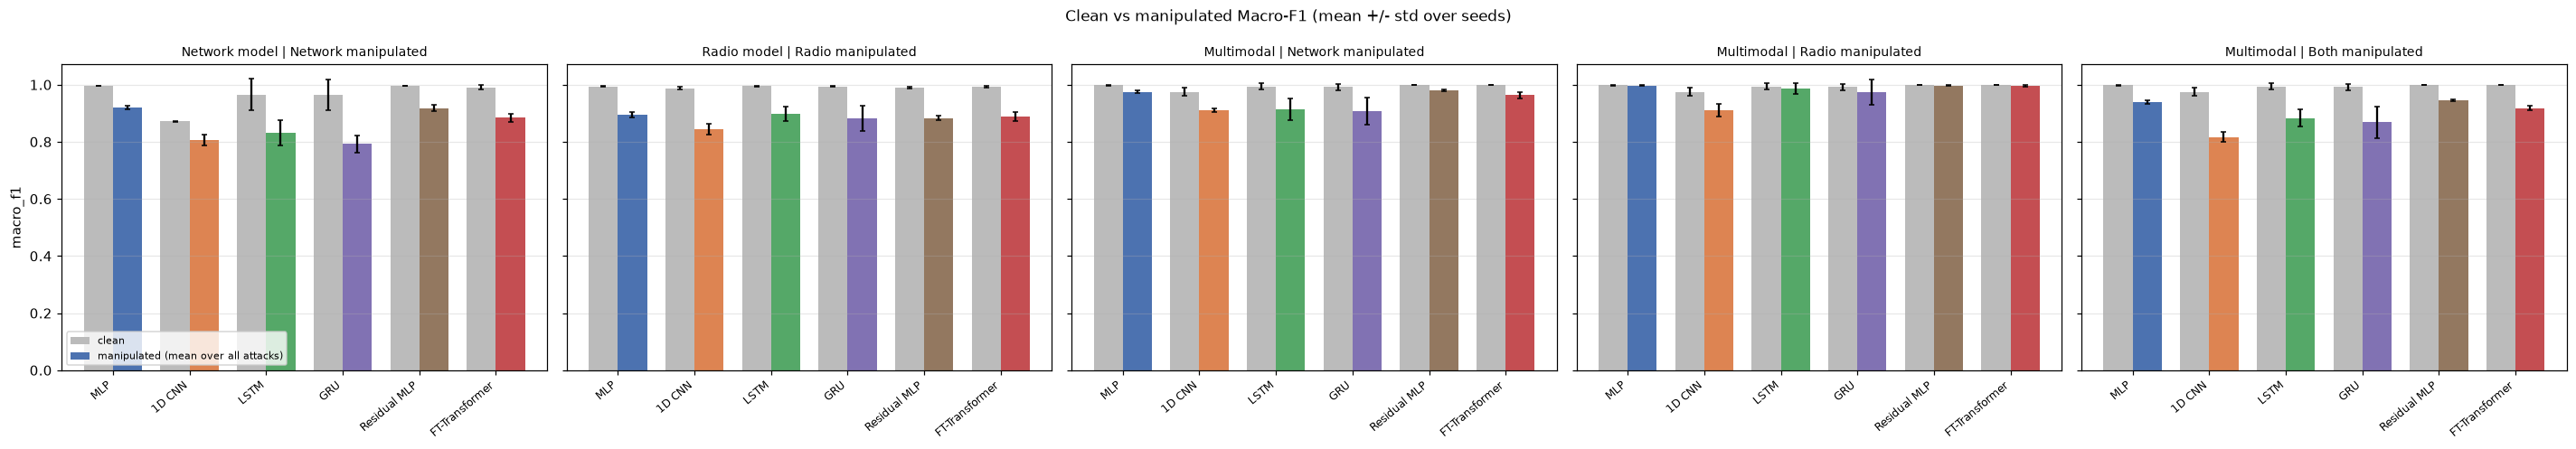

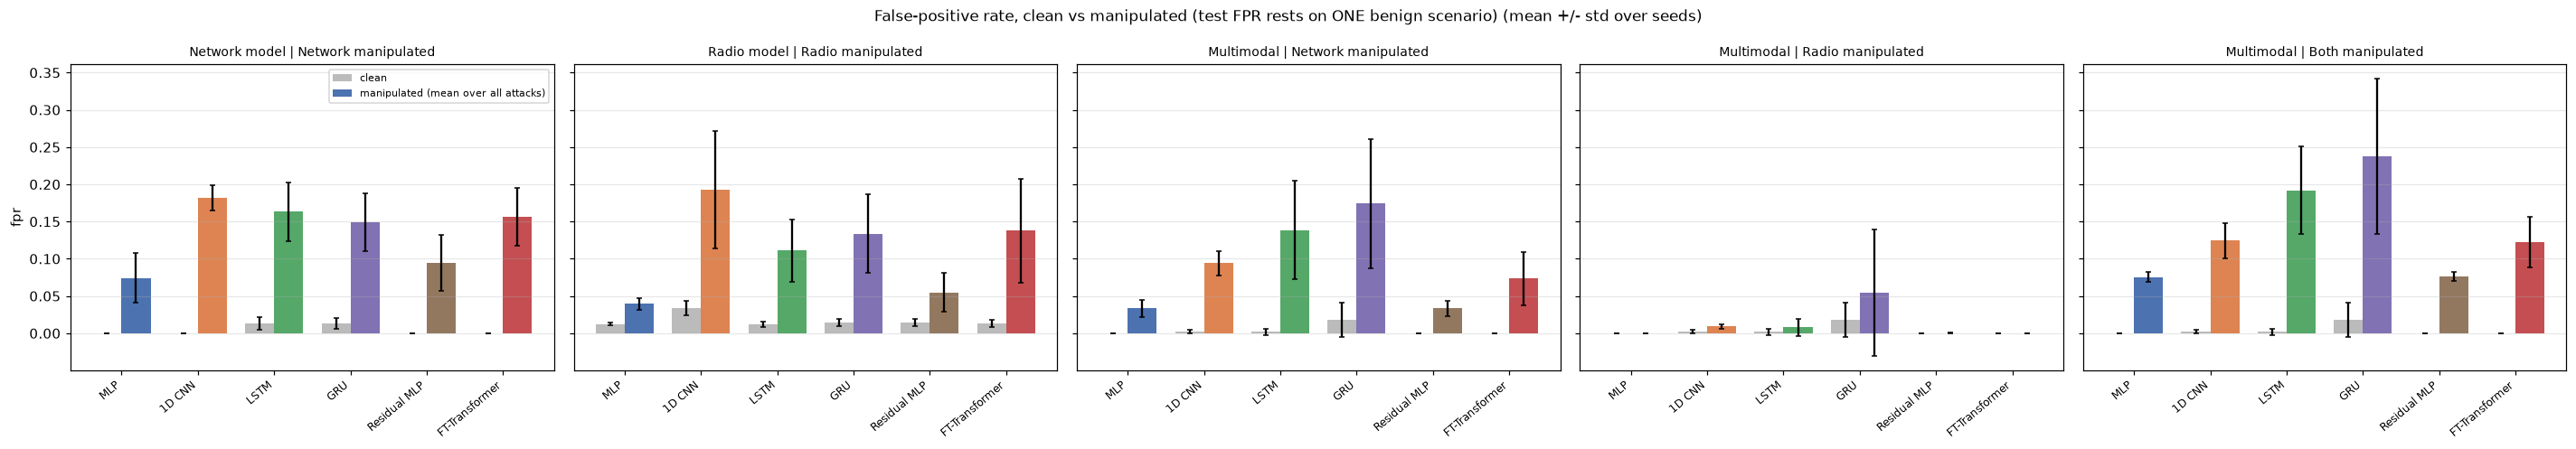

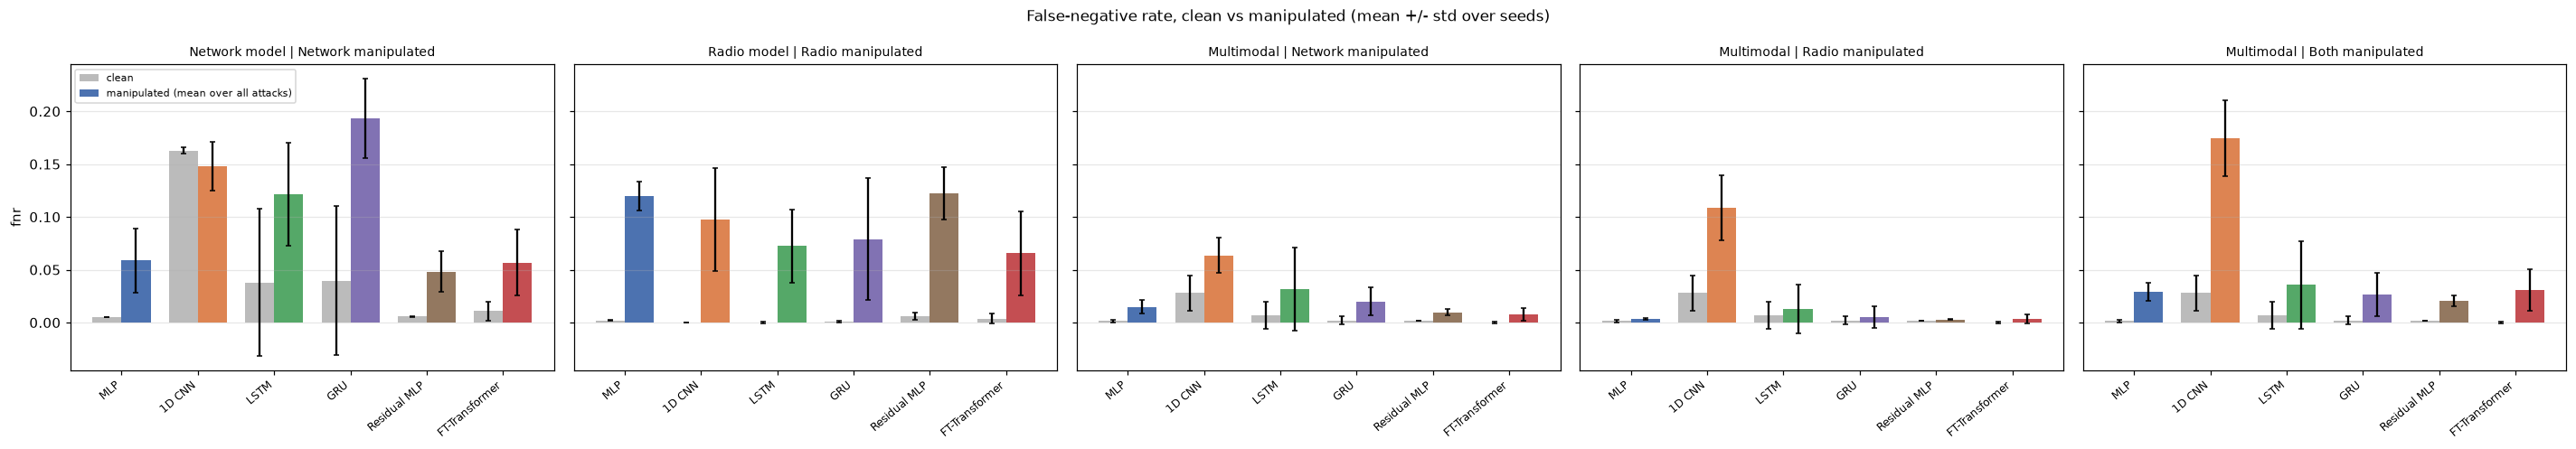

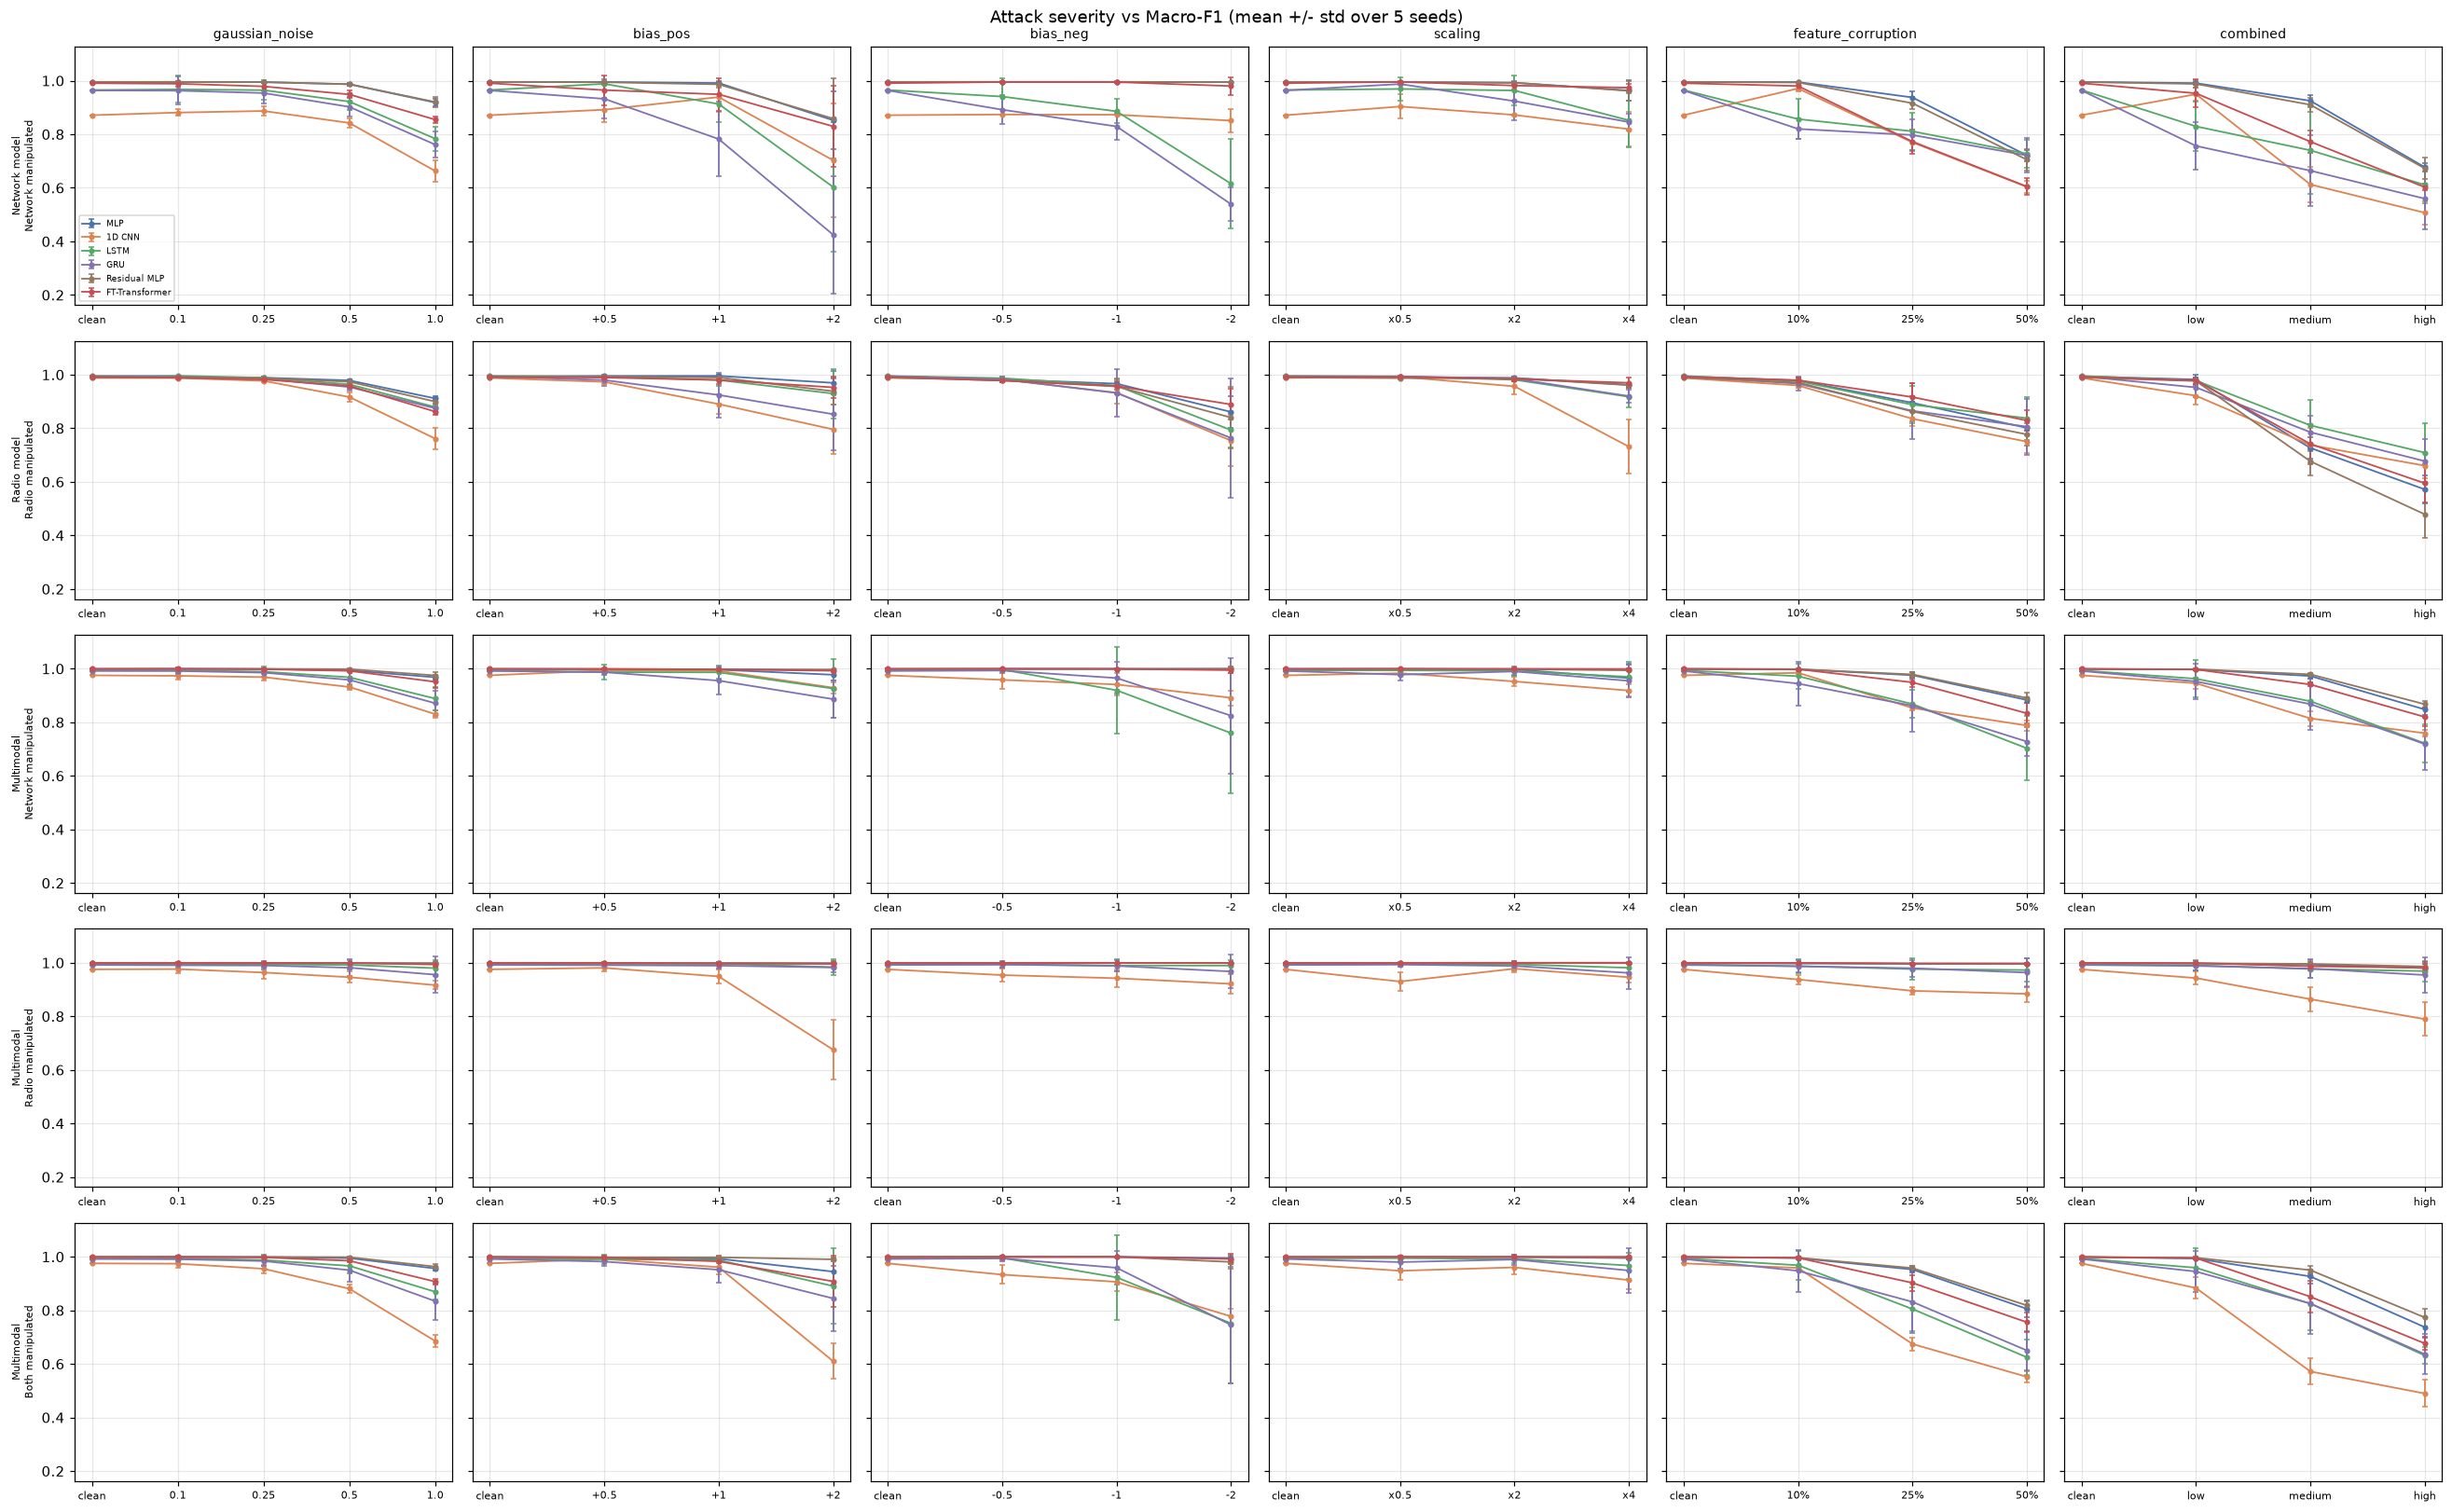

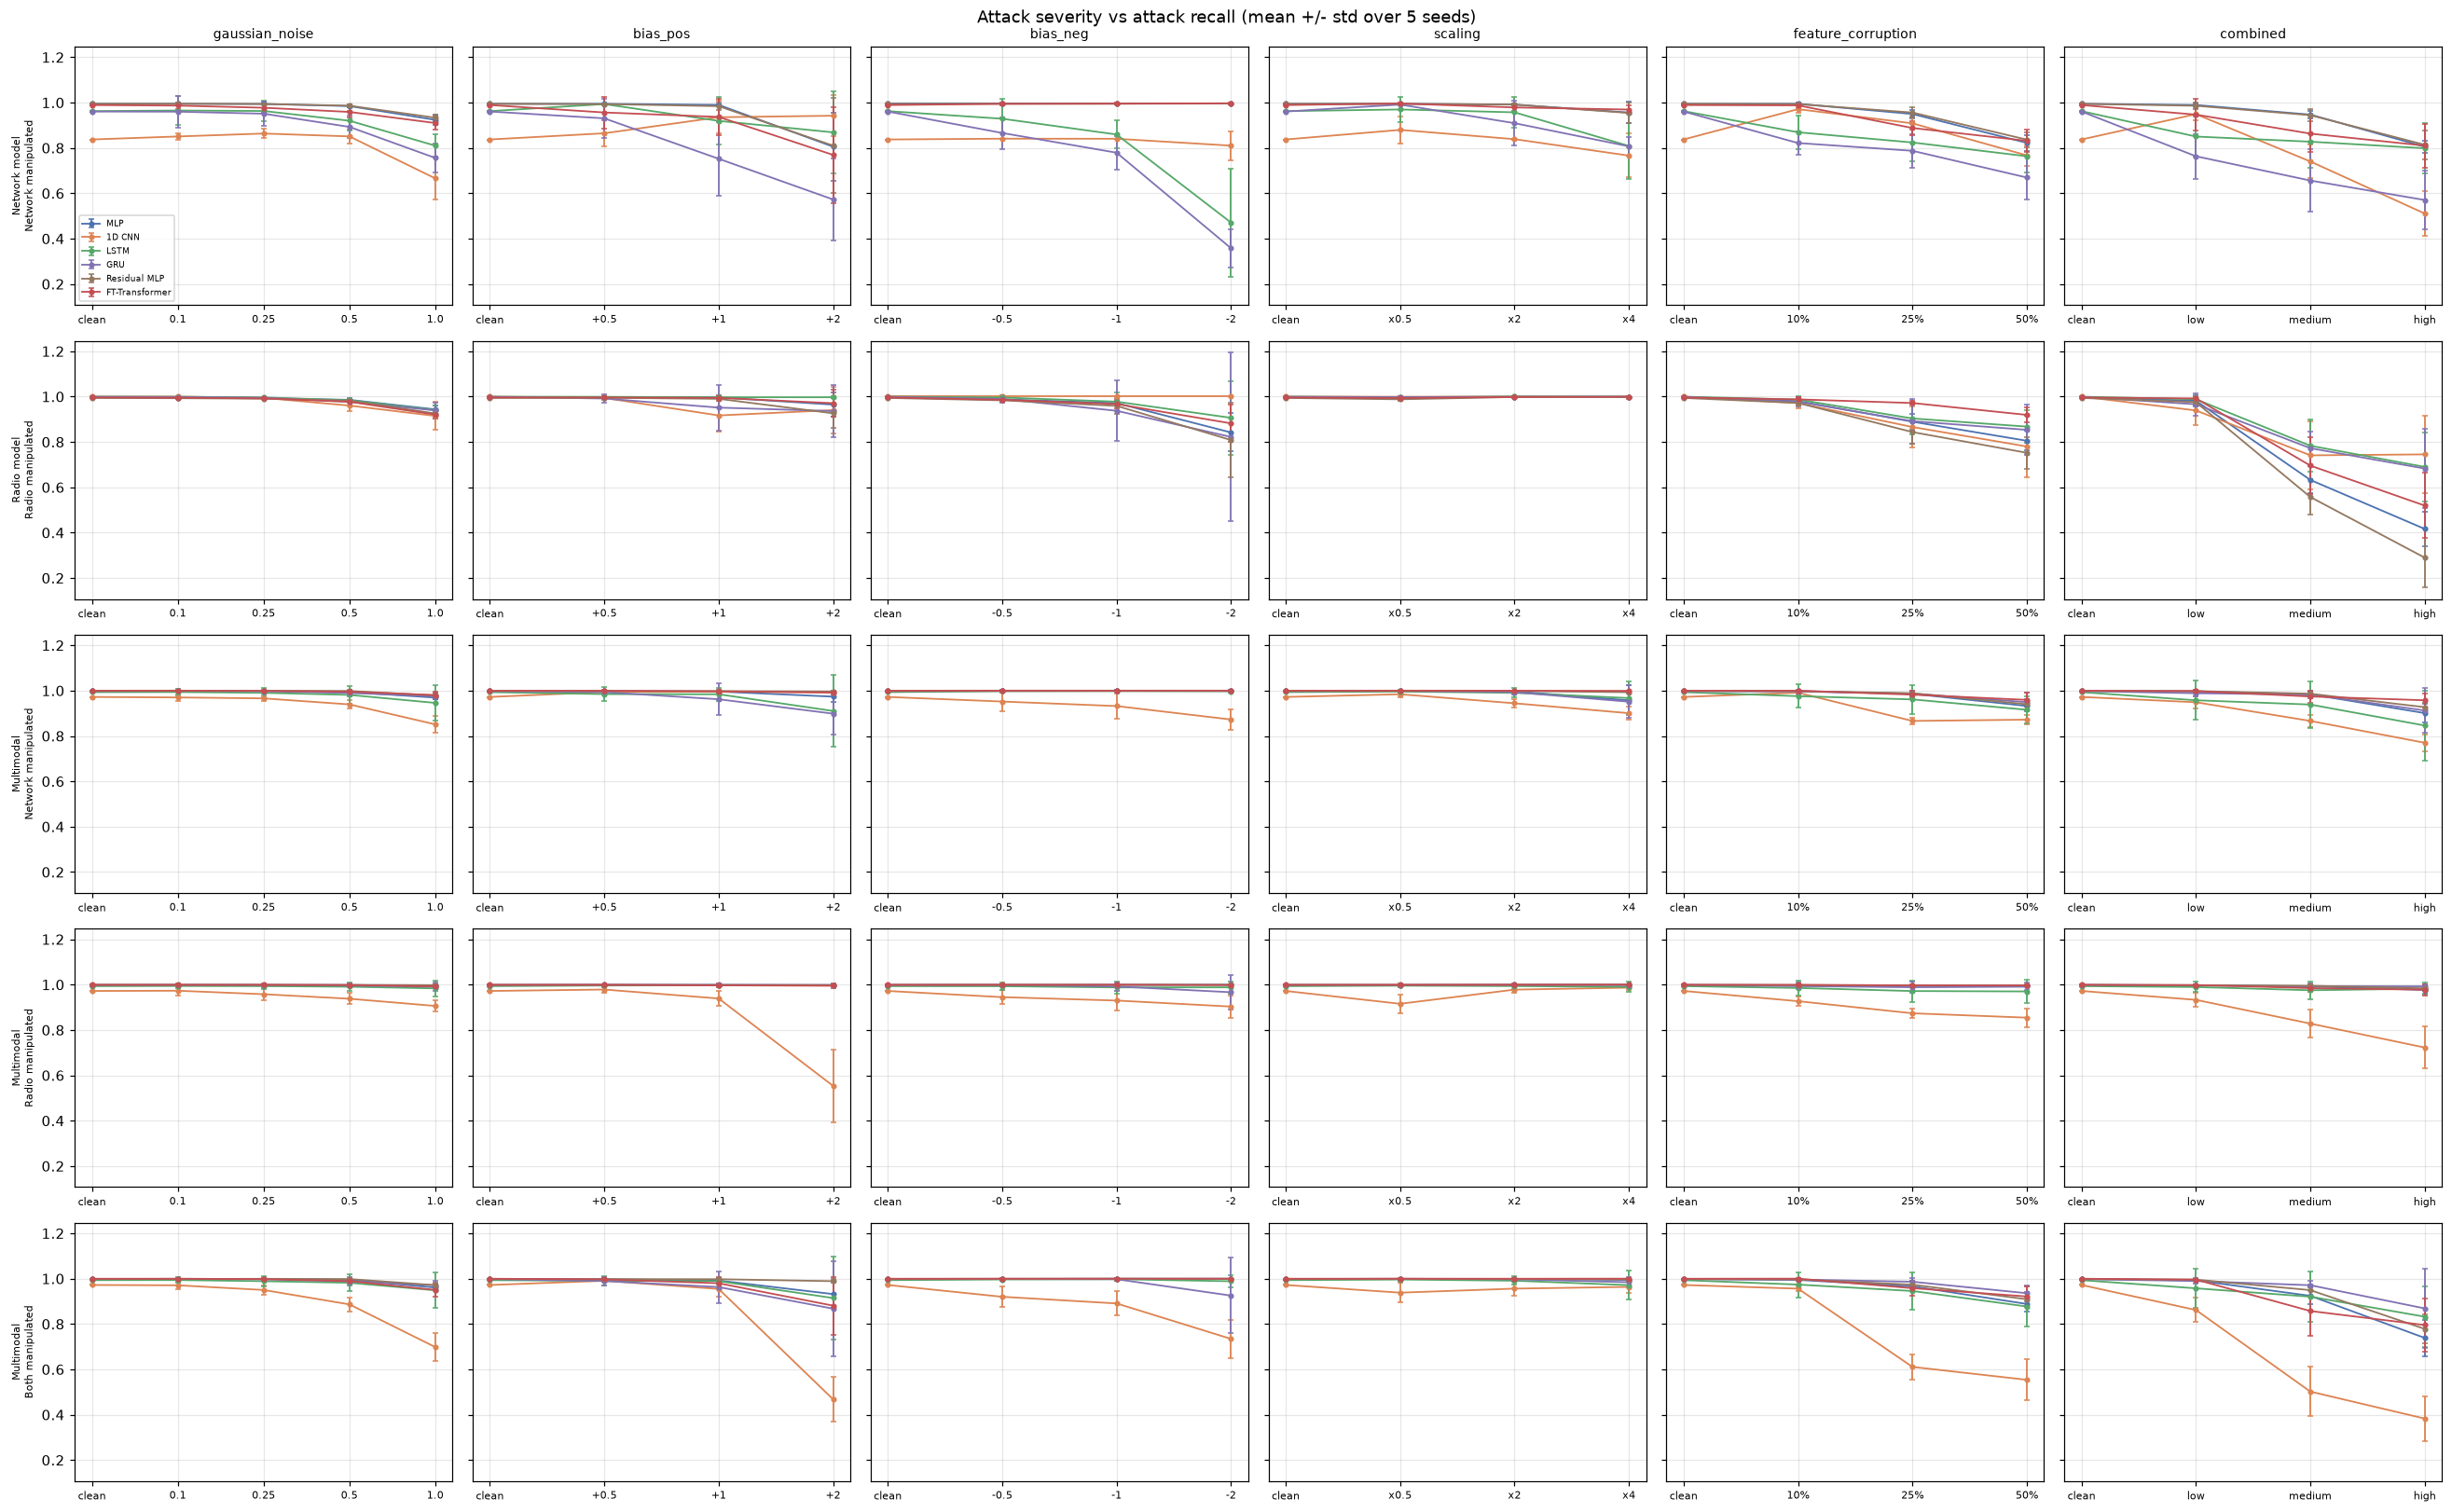

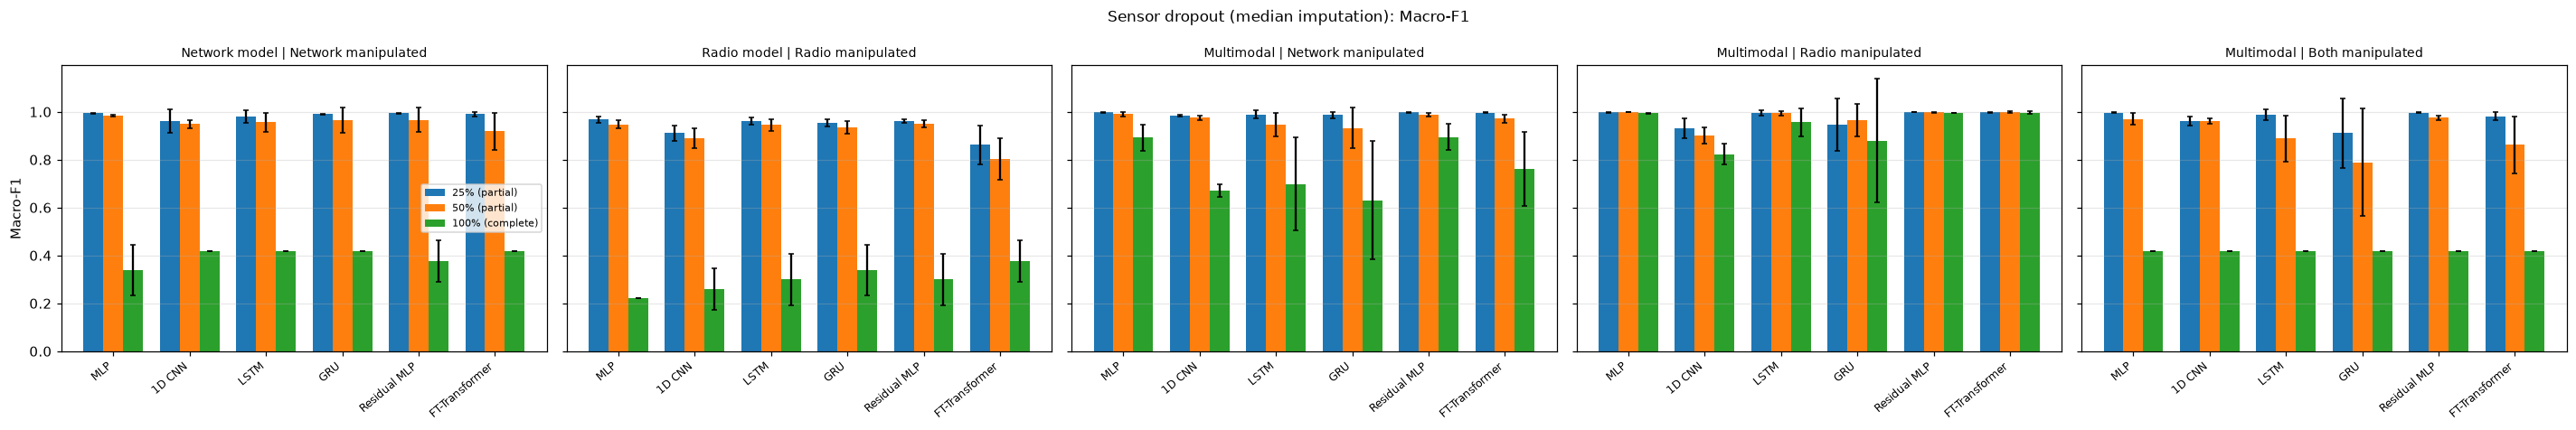

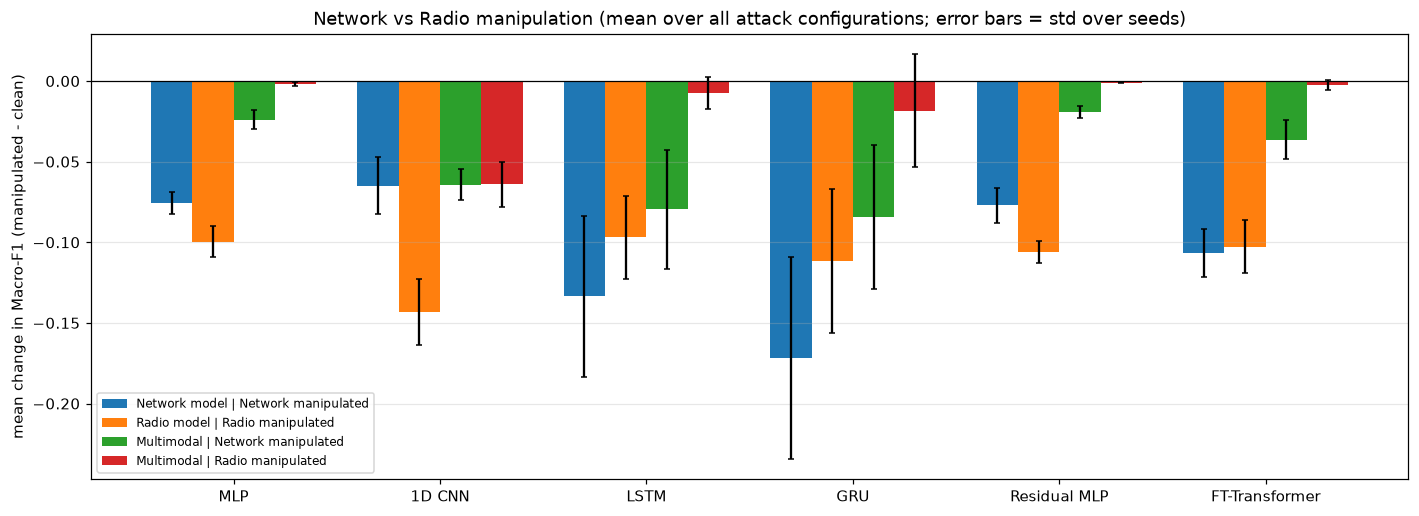

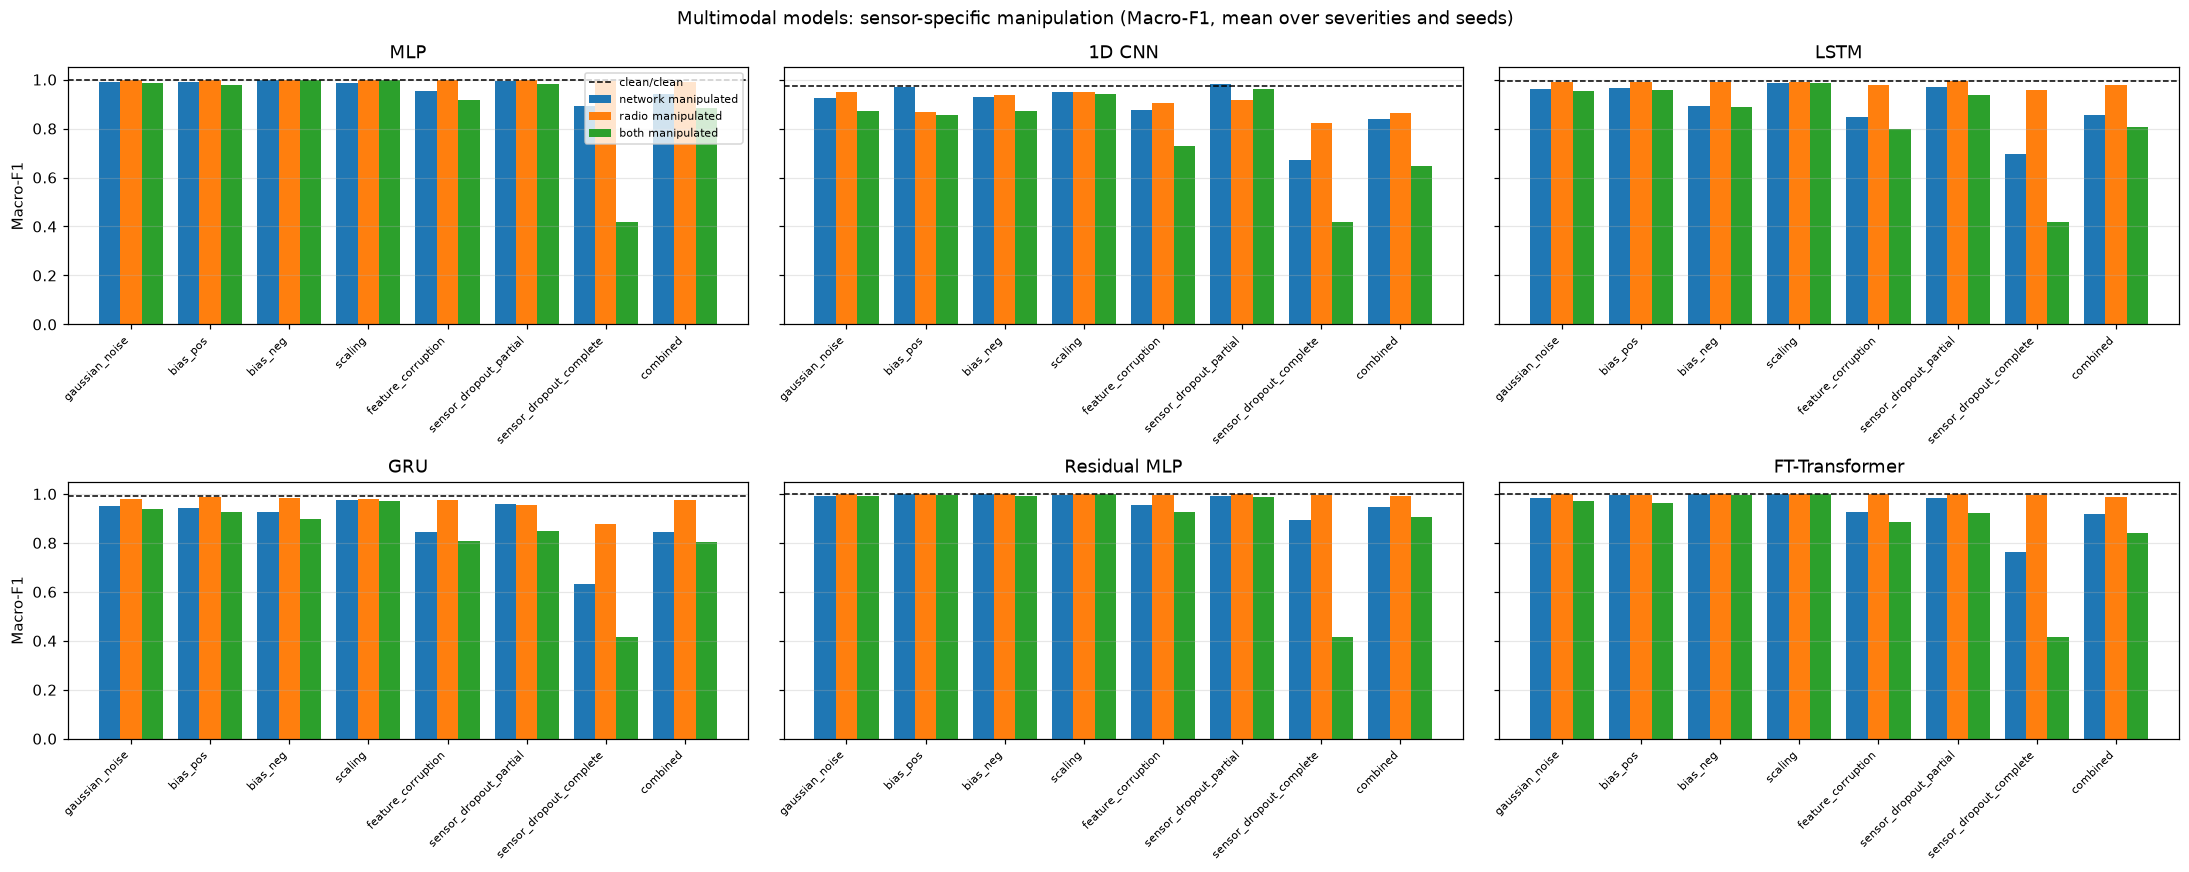

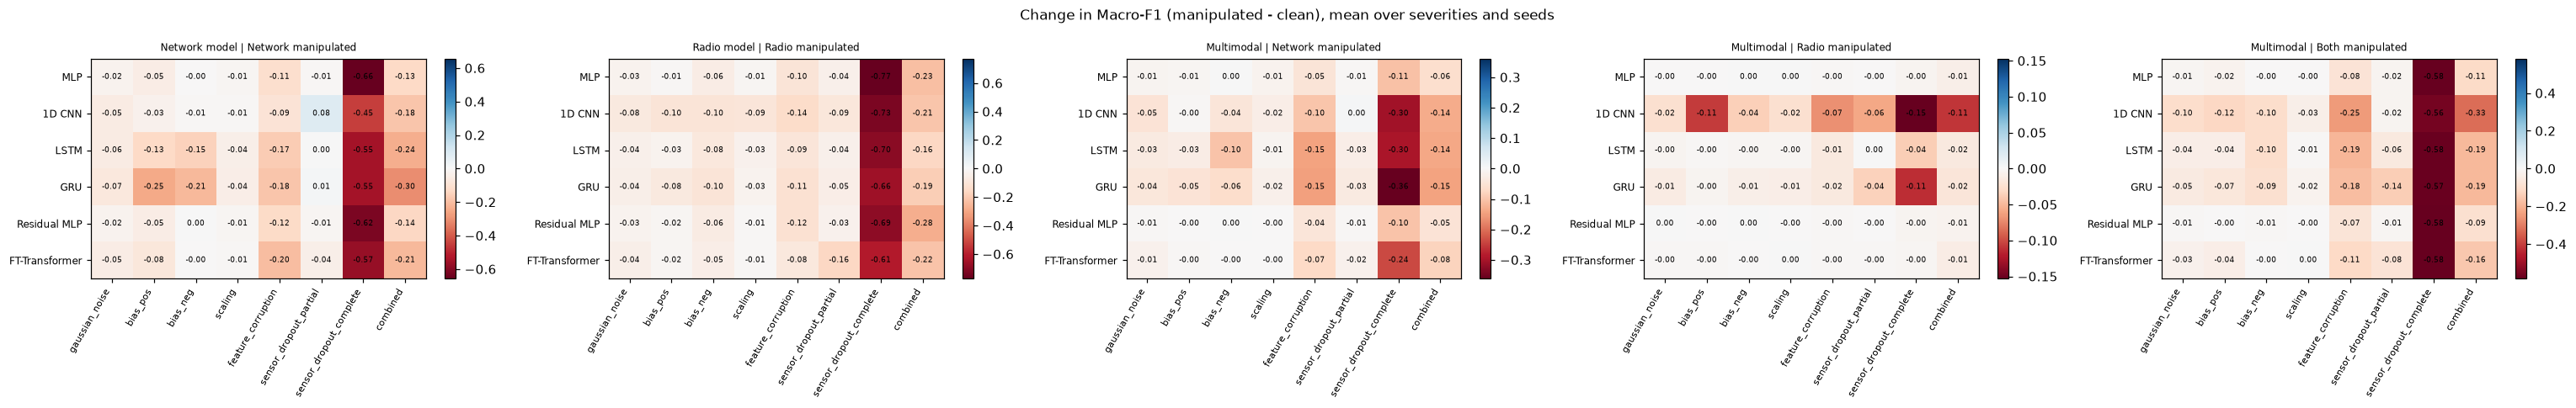

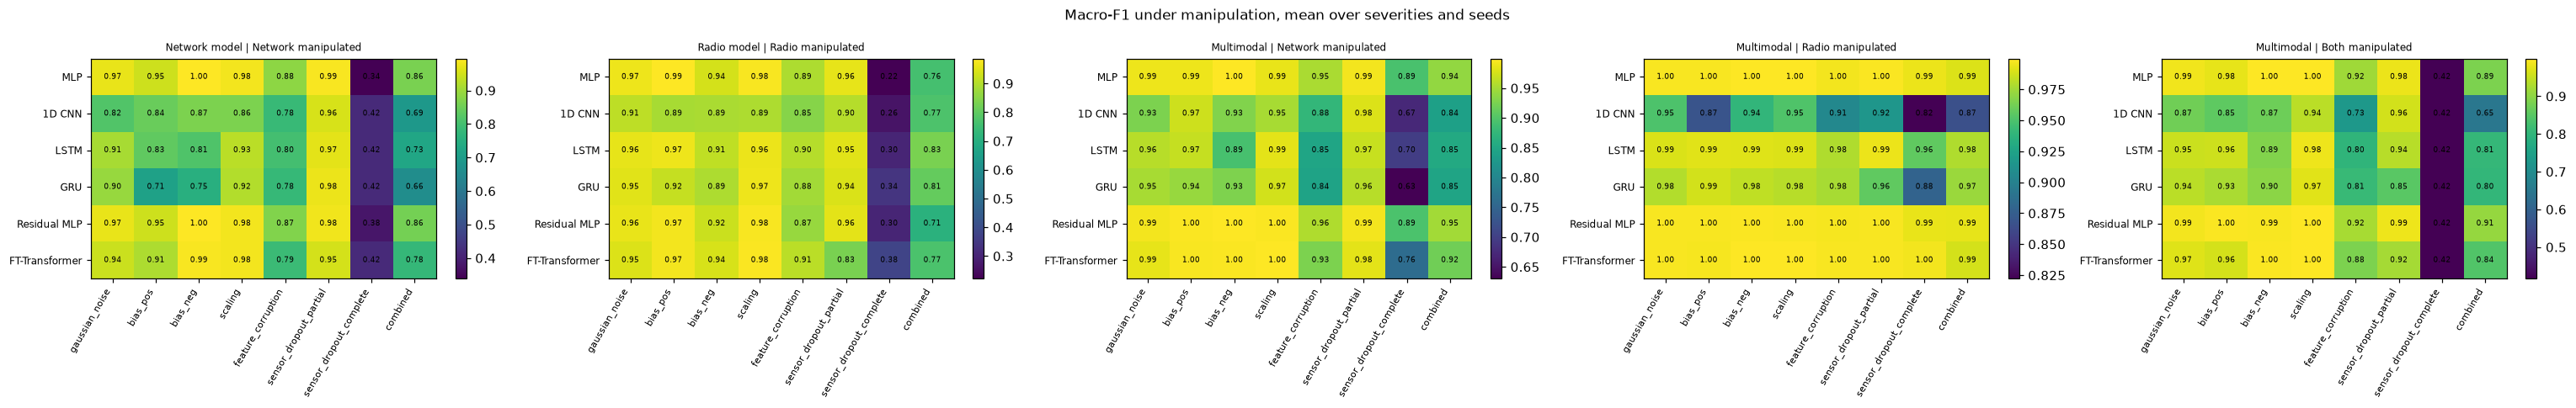

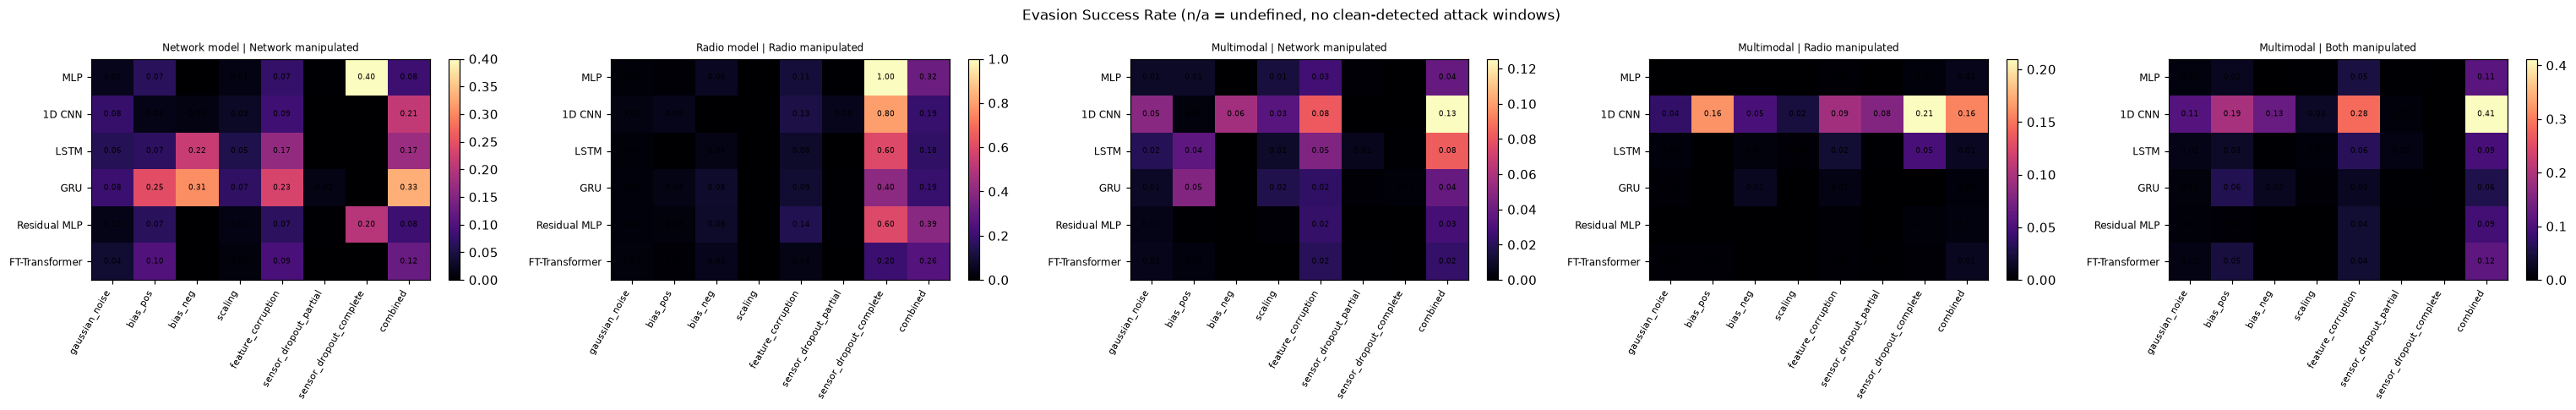

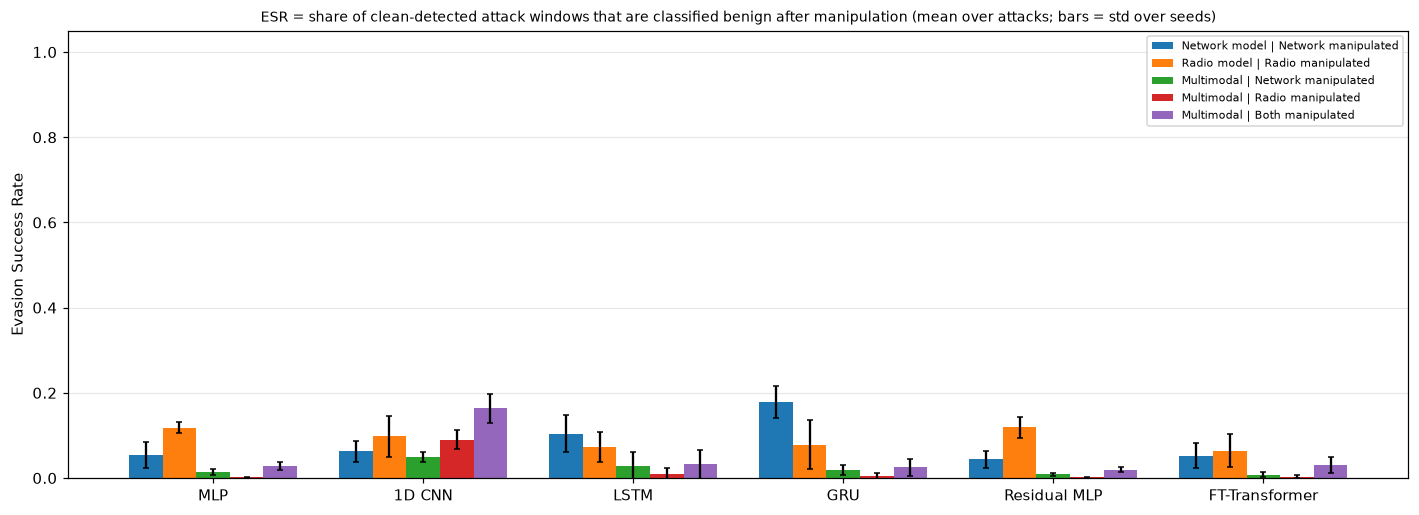

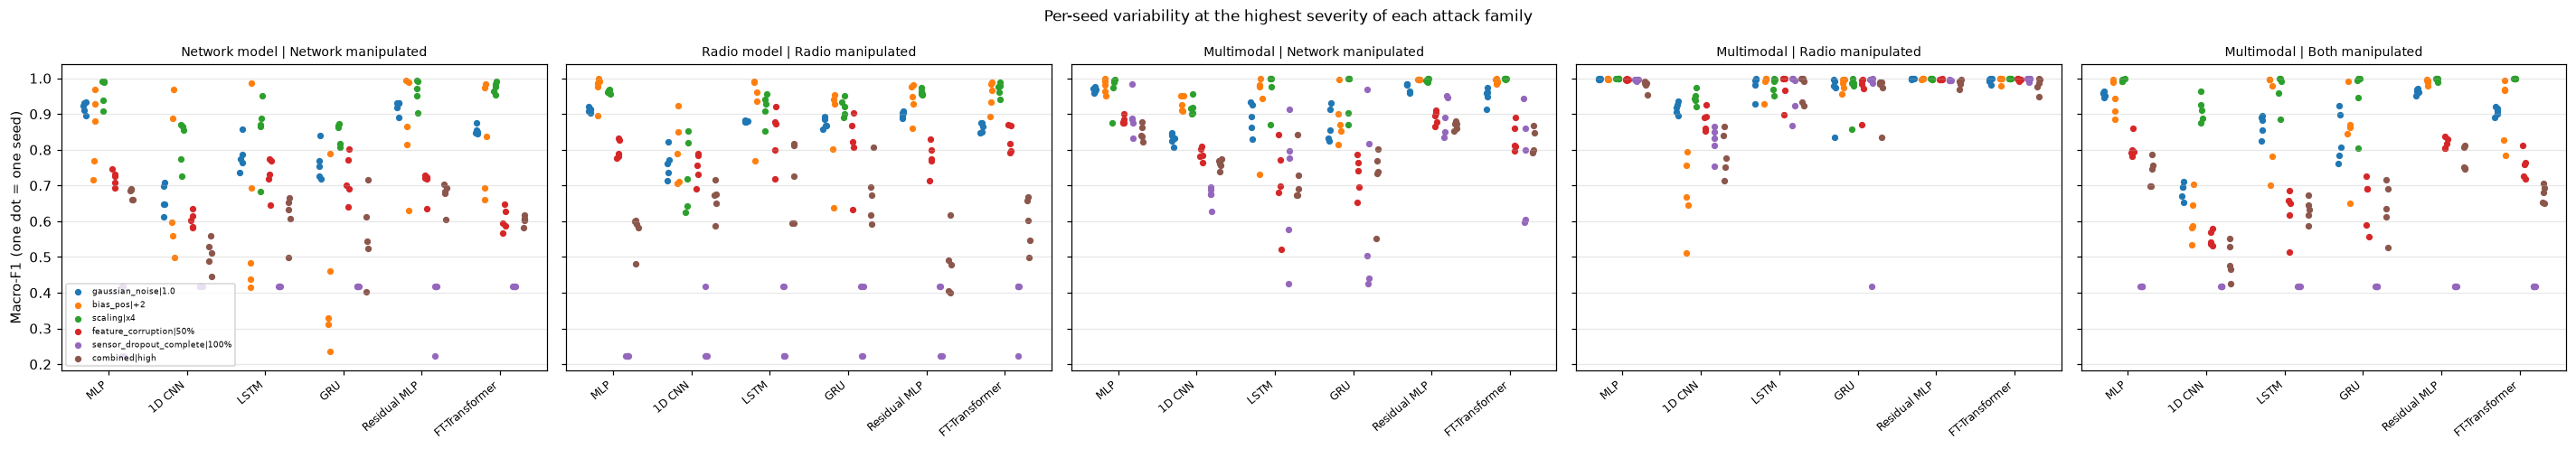

plots: ['fig_clean_vs_manipulated_macro_f1.png', 'fig_fpr_clean_vs_manipulated.png', 'fig_fnr_clean_vs_manipulated.png', 'fig_severity_vs_macro_f1.png', 'fig_severity_vs_attack_recall.png', 'fig_sensor_dropout_macro_f1.png', 'fig_network_vs_radio_manipulation.png', 'fig_multimodal_sensor_specific.png', 'fig_heatmap_delta_macro_f1.png', 'fig_heatmap_macro_f1.png', 'fig_heatmap_esr.png', 'fig_evasion_success_rate.png', 'fig_per_seed_variability.png']


In [14]:
PLOTS = []
def save_fig(fig, name):
    fig.savefig(OUT / name, dpi=110, bbox_inches="tight"); plt.close(fig); PLOTS.append(name); display(Image(filename=str(OUT / name)))

def clean_vs_attacked_bars(metric, fname, title):
    fig, axes = plt.subplots(1, 5, figsize=(26, 4.6), sharey=True)
    for ax, (m, t) in zip(axes, CONDITIONS):
        cond = f"{m}:{t}"; x = np.arange(len(ARCHS)); w = 0.38
        d = COND_SEED[COND_SEED.cond == cond].groupby("architecture")
        att = d[metric].agg(["mean", "std"]).reindex(ARCHS); cl = d[f"clean_{metric}"].agg(["mean", "std"]).reindex(ARCHS)
        ax.bar(x - w / 2, cl["mean"], w, yerr=cl["std"].fillna(0), capsize=2, color="#bbbbbb", label="clean")
        ax.bar(x + w / 2, att["mean"], w, yerr=att["std"].fillna(0), capsize=2, color=[ARCH_COLORS[a] for a in ARCHS], label="manipulated (mean over all attacks)")
        ax.set_xticks(x); ax.set_xticklabels([ARCH_LABEL[a] for a in ARCHS], rotation=40, ha="right", fontsize=8); ax.set_title(COND_LABEL[(m, t)], fontsize=9); ax.grid(axis="y", alpha=0.3)
    axes[0].set_ylabel(metric); axes[0].legend(fontsize=7); fig.suptitle(title + " (mean +/- std over seeds)", fontsize=11); fig.tight_layout(); save_fig(fig, fname)

clean_vs_attacked_bars("macro_f1", "fig_clean_vs_manipulated_macro_f1.png", "Clean vs manipulated Macro-F1")
clean_vs_attacked_bars("fpr", "fig_fpr_clean_vs_manipulated.png", "False-positive rate, clean vs manipulated (test FPR rests on ONE benign scenario)")
clean_vs_attacked_bars("fnr", "fig_fnr_clean_vs_manipulated.png", "False-negative rate, clean vs manipulated")

FAMS = ["gaussian_noise", "bias_pos", "bias_neg", "scaling", "feature_corruption", "combined"]
def severity_plot(metric, fname, ylabel):
    fig, axes = plt.subplots(len(CONDITIONS), len(FAMS), figsize=(4.0 * len(FAMS), 3.0 * len(CONDITIONS)), sharey=True, squeeze=False)
    for r, (m, t) in enumerate(CONDITIONS):
        for c, fam in enumerate(FAMS):
            ax = axes[r, c]; sev = [a["severity"] for a in ATTACK_GRID if a["attack_type"] == fam]
            for a in ARCHS:
                d = SUMMARY[(SUMMARY.architecture == a) & (SUMMARY.modality == m) & (SUMMARY.attack_target == t) & (SUMMARY.attack_type == fam)].sort_values("severity_rank")
                if d.empty: continue
                cl = CLEAN_DF[(CLEAN_DF.architecture == a) & (CLEAN_DF.modality == m)][metric].mean()
                ys = np.r_[cl, d[f"{metric}_mean"].to_numpy()]; es = np.r_[0, np.nan_to_num(d[f"{metric}_std"].to_numpy())]
                ax.errorbar(np.arange(len(ys)), ys, yerr=es, marker="o", ms=3, lw=1.2, capsize=2, color=ARCH_COLORS[a], label=ARCH_LABEL[a])
            ax.set_xticks(range(len(sev) + 1)); ax.set_xticklabels(["clean"] + sev, fontsize=7); ax.grid(alpha=0.3)
            if r == 0: ax.set_title(fam, fontsize=9)
            if c == 0: ax.set_ylabel(COND_LABEL[(m, t)].replace(" | ", "\n"), fontsize=7)
    axes[0, 0].legend(fontsize=6); fig.suptitle(f"Attack severity vs {ylabel} (mean +/- std over 5 seeds)", fontsize=12); fig.tight_layout(); save_fig(fig, fname)

severity_plot("macro_f1", "fig_severity_vs_macro_f1.png", "Macro-F1")
severity_plot("recall", "fig_severity_vs_attack_recall.png", "attack recall")

# sensor dropout (partial / complete)
fig, axes = plt.subplots(1, 5, figsize=(26, 4.4), sharey=True); drop_ids = ["sensor_dropout_partial|25%", "sensor_dropout_partial|50%", "sensor_dropout_complete|100%"]
for ax, (m, t) in zip(axes, CONDITIONS):
    x = np.arange(len(ARCHS)); w = 0.26
    for j, aid in enumerate(drop_ids):
        d = SUMMARY[(SUMMARY.modality == m) & (SUMMARY.attack_target == t) & (SUMMARY.attack_id == aid)].set_index("architecture").reindex(ARCHS)
        ax.bar(x + (j - 1) * w, d["macro_f1_mean"], w, yerr=d["macro_f1_std"].fillna(0), capsize=2, label=aid.split("|")[1] + (" (partial)" if "partial" in aid else " (complete)"))
    ax.set_xticks(x); ax.set_xticklabels([ARCH_LABEL[a] for a in ARCHS], rotation=40, ha="right", fontsize=8); ax.set_title(COND_LABEL[(m, t)], fontsize=9); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Macro-F1"); axes[0].legend(fontsize=7); fig.suptitle("Sensor dropout (median imputation): Macro-F1", fontsize=11); fig.tight_layout(); save_fig(fig, "fig_sensor_dropout_macro_f1.png")

# Network vs Radio manipulation
fig, ax = plt.subplots(figsize=(13, 4.8)); x = np.arange(len(ARCHS)); w = 0.2
for j, (m, t) in enumerate([("network", "network"), ("radio", "radio"), ("multimodal", "network"), ("multimodal", "radio")]):
    d = COND_SEED[COND_SEED.cond == f"{m}:{t}"].groupby("architecture")["delta_macro_f1"].agg(["mean", "std"]).reindex(ARCHS)
    ax.bar(x + (j - 1.5) * w, d["mean"], w, yerr=d["std"].fillna(0), capsize=2, label=COND_LABEL[(m, t)])
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x); ax.set_xticklabels([ARCH_LABEL[a] for a in ARCHS]); ax.set_ylabel("mean change in Macro-F1 (manipulated - clean)")
ax.set_title("Network vs Radio manipulation (mean over all attack configurations; error bars = std over seeds)"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3); fig.tight_layout(); save_fig(fig, "fig_network_vs_radio_manipulation.png")

# multimodal sensor-specific robustness, per architecture
fig, axes = plt.subplots(2, 3, figsize=(20, 8), sharey=True)
for ax, a in zip(axes.ravel(), ARCHS):
    x = np.arange(len(FAMILY_ORDER)); w = 0.27
    for j, t in enumerate(["network", "radio", "both"]):
        d = PER_SEED[(PER_SEED.architecture == a) & (PER_SEED.modality == "multimodal") & (PER_SEED.attack_target == t)].groupby("attack_type")["macro_f1"].mean().reindex(FAMILY_ORDER)
        ax.bar(x + (j - 1) * w, d.values, w, label=f"{t} manipulated")
    ax.axhline(CLEAN_DF[(CLEAN_DF.architecture == a) & (CLEAN_DF.modality == "multimodal")].macro_f1.mean(), color="k", ls="--", lw=1, label="clean/clean")
    ax.set_xticks(x); ax.set_xticklabels(FAMILY_ORDER, rotation=45, ha="right", fontsize=7); ax.set_title(ARCH_LABEL[a]); ax.grid(axis="y", alpha=0.3)
axes[0, 0].legend(fontsize=7); axes[0, 0].set_ylabel("Macro-F1"); axes[1, 0].set_ylabel("Macro-F1")
fig.suptitle("Multimodal models: sensor-specific manipulation (Macro-F1, mean over severities and seeds)", fontsize=12); fig.tight_layout(); save_fig(fig, "fig_multimodal_sensor_specific.png")

# architecture robustness heatmaps
def family_heatmap(metric, fname, title, cmap, center=None):
    fig, axes = plt.subplots(1, 5, figsize=(28, 4.4))
    for ax, (m, t) in zip(axes, CONDITIONS):
        d = PER_SEED[PER_SEED.cond == f"{m}:{t}"].groupby(["architecture", "attack_type"])[metric].mean().unstack().reindex(index=ARCHS, columns=FAMILY_ORDER)
        v = d.to_numpy(float); vmax = np.nanmax(np.abs(v)) if center is not None and np.isfinite(v).any() else None
        im = ax.imshow(v, cmap=cmap, aspect="auto", vmin=(-vmax if vmax else None), vmax=(vmax if vmax else None))
        ax.set_xticks(range(len(FAMILY_ORDER))); ax.set_xticklabels(FAMILY_ORDER, rotation=60, ha="right", fontsize=7); ax.set_yticks(range(len(ARCHS))); ax.set_yticklabels([ARCH_LABEL[a] for a in ARCHS], fontsize=8)
        for i in range(v.shape[0]):
            for j in range(v.shape[1]): ax.text(j, i, "n/a" if np.isnan(v[i, j]) else f"{v[i, j]:.2f}", ha="center", va="center", fontsize=6)
        ax.set_title(COND_LABEL[(m, t)], fontsize=8); fig.colorbar(im, ax=ax, fraction=0.04)
    fig.suptitle(title, fontsize=11); fig.tight_layout(); save_fig(fig, fname)
family_heatmap("delta_macro_f1", "fig_heatmap_delta_macro_f1.png", "Change in Macro-F1 (manipulated - clean), mean over severities and seeds", "RdBu", center=0)
family_heatmap("macro_f1", "fig_heatmap_macro_f1.png", "Macro-F1 under manipulation, mean over severities and seeds", "viridis")
family_heatmap("esr", "fig_heatmap_esr.png", "Evasion Success Rate (n/a = undefined, no clean-detected attack windows)", "magma")

# ESR comparison
fig, ax = plt.subplots(figsize=(13, 4.8)); w = 0.16
for j, (m, t) in enumerate(CONDITIONS):
    d = COND_SEED[COND_SEED.cond == f"{m}:{t}"].groupby("architecture")["esr"].agg(["mean", "std"]).reindex(ARCHS)
    ax.bar(np.arange(len(ARCHS)) + (j - 2) * w, d["mean"], w, yerr=d["std"].fillna(0), capsize=2, label=COND_LABEL[(m, t)])
ax.set_xticks(np.arange(len(ARCHS))); ax.set_xticklabels([ARCH_LABEL[a] for a in ARCHS]); ax.set_ylabel("Evasion Success Rate"); ax.set_ylim(0, 1.05)
ax.set_title("ESR = share of clean-detected attack windows that are classified benign after manipulation (mean over attacks; bars = std over seeds)", fontsize=9)
ax.legend(fontsize=7); ax.grid(axis="y", alpha=0.3); fig.tight_layout(); save_fig(fig, "fig_evasion_success_rate.png")

# per-seed variability at a-priori reference severities (highest severity of each family; fixed before any result)
REF = ["gaussian_noise|1.0", "bias_pos|+2", "scaling|x4", "feature_corruption|50%", "sensor_dropout_complete|100%", "combined|high"]
fig, axes = plt.subplots(1, 5, figsize=(26, 4.6), sharey=True); rng_j = np.random.default_rng(0)
for ax, (m, t) in zip(axes, CONDITIONS):
    for k, aid in enumerate(REF):
        d = PER_SEED[(PER_SEED.cond == f"{m}:{t}") & (PER_SEED.attack_id == aid)]
        for ai, a in enumerate(ARCHS):
            v = d[d.architecture == a]["macro_f1"].to_numpy()
            ax.scatter(ai + (k - 2.5) * 0.12 + rng_j.uniform(-0.02, 0.02, len(v)), v, s=14, color=plt.cm.tab10(k), label=aid if ai == 0 else None)
    ax.set_xticks(range(len(ARCHS))); ax.set_xticklabels([ARCH_LABEL[a] for a in ARCHS], rotation=40, ha="right", fontsize=8); ax.set_title(COND_LABEL[(m, t)], fontsize=9); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Macro-F1 (one dot = one seed)"); axes[0].legend(fontsize=6); fig.suptitle("Per-seed variability at the highest severity of each attack family", fontsize=11); fig.tight_layout(); save_fig(fig, "fig_per_seed_variability.png")
print("plots:", PLOTS)

## 15. Research discussion and limitations
Every statement below is **generated from the measured results of this run** (no numbers are hard-coded). They are descriptive stress-test observations on a tiny, confounded test set; none of them certifies a model as robust.

In [15]:
def cs(metric, cond): return COND_SEED[COND_SEED.cond == cond].groupby("architecture")[metric].mean().reindex(ARCHS)
def fmt(s, nd=3): return ", ".join(f"{ARCH_LABEL[a]} {s[a]:+.{nd}f}" if np.isfinite(s[a]) else f"{ARCH_LABEL[a]} n/a" for a in s.index)
def fmt_num(v, signed=False): return "n/a" if not np.isfinite(v) else (f"{v:+.3f}" if signed else f"{v:.3f}")
def fmt_pct(v): return "n/a" if not np.isfinite(v) else f"{v:.1%}"
def arch_label(a): return ARCH_LABEL.get(a, "n/a")
def safe_extreme(s, kind):
    s = pd.Series(s).dropna()
    if s.empty: return None, float("nan")
    a = s.idxmin() if kind == "min" else s.idxmax()
    return a, float(s.loc[a])
ANALYSIS, tables = {}, {}

# Q1 / Q2: sensitivity to Network / Radio manipulation (mean change in Macro-F1; more negative = more sensitive)
for q, cands in [("Q1_network", [("network", "network"), ("multimodal", "network")]), ("Q2_radio", [("radio", "radio"), ("multimodal", "radio")])]:
    tbl = pd.DataFrame({f"{m}:{t}": cs("delta_macro_f1", f"{m}:{t}") for m, t in cands}); tables[q] = tbl; display(tbl.round(4).rename(index=ARCH_LABEL))
    lines = []
    for c in tbl.columns:
        a_lo, v_lo = safe_extreme(tbl[c], "min"); a_hi, v_hi = safe_extreme(tbl[c], "max")
        lines.append(f"{c}: most sensitive = {arch_label(a_lo)} (mean change in Macro-F1 {fmt_num(v_lo, True)}); least affected = {arch_label(a_hi)} ({fmt_num(v_hi, True)})")
    ANALYSIS[q] = lines; print(q, *lines, sep="\n  ")

# Q3: does manipulating ONE sensor affect multimodal performance?
d3 = pd.DataFrame({"clean_macro_f1": COND_SEED[COND_SEED.cond == "multimodal:network"].groupby("architecture")["clean_macro_f1"].mean(),
                   "net_manip_macro_f1": cs("macro_f1", "multimodal:network"), "radio_manip_macro_f1": cs("macro_f1", "multimodal:radio")}).reindex(ARCHS)
tables["Q3"] = d3; display(d3.round(4).rename(index=ARCH_LABEL))
ANALYSIS["Q3"] = [f"Mean Macro-F1 of the multimodal models: clean {fmt_num(d3.clean_macro_f1.mean())}, Network manipulated {fmt_num(d3.net_manip_macro_f1.mean())}, Radio manipulated {fmt_num(d3.radio_manip_macro_f1.mean())} (averaged over architectures, attack configurations and seeds).",
                  "Share of (architecture, seed, attack) cases where Macro-F1 falls by more than 0.05 (arbitrary descriptive cut-off): " +
                  ", ".join(f"{t}: {fmt_pct((PER_SEED[PER_SEED.cond == 'multimodal:' + t].delta_macro_f1 < -0.05).mean())}" for t in ["network", "radio", "both"])]
print(*ANALYSIS["Q3"], sep="\n")

# Q4: Network vs Radio manipulation damage (multimodal models, and single-modality models)
dn, dr = cs("delta_macro_f1", "multimodal:network"), cs("delta_macro_f1", "multimodal:radio")
fam_n = PER_SEED[PER_SEED.cond == "multimodal:network"].groupby("attack_type")["delta_macro_f1"].mean(); fam_r = PER_SEED[PER_SEED.cond == "multimodal:radio"].groupby("attack_type")["delta_macro_f1"].mean()
tables["Q4_family"] = pd.DataFrame({"network": fam_n, "radio": fam_r}).reindex(FAMILY_ORDER); display(tables["Q4_family"].round(4))
n_net_worse = int((dn < dr).sum()); n_fam_net_worse = int((fam_n < fam_r).sum())
ANALYSIS["Q4"] = [f"Multimodal: Network manipulation lowers mean Macro-F1 more than Radio manipulation for {n_net_worse}/{len(ARCHS)} architectures (Network {fmt_num(dn.mean(), True)} vs Radio {fmt_num(dr.mean(), True)} on average) and for {n_fam_net_worse}/{len(fam_n)} attack families.",
                  "Per architecture, change in Macro-F1 - Network: " + fmt(dn) + " | Radio: " + fmt(dr)]
print(*ANALYSIS["Q4"], sep="\n")

# Q5: both sensors vs single sensor
db = cs("delta_macro_f1", "multimodal:both"); worst_single = pd.concat([dn, dr], axis=1).min(axis=1)
tables["Q5"] = pd.DataFrame({"network": dn, "radio": dr, "both": db, "worst_single": worst_single}); display(tables["Q5"].round(4).rename(index=ARCH_LABEL))
ANALYSIS["Q5"] = [f"Manipulating both sensors gives a lower mean Macro-F1 than the worse single-sensor manipulation for {int((db < worst_single).sum())}/{len(ARCHS)} architectures (mean change: both {fmt_num(db.mean(), True)}, worse single {fmt_num(worst_single.mean(), True)})."]
print(*ANALYSIS["Q5"], sep="\n")

# Q6: highest attack recall under manipulation
rec = pd.DataFrame({f"{m}:{t}": cs("recall", f"{m}:{t}") for m, t in CONDITIONS}); tables["Q6"] = rec; display(rec.round(4).rename(index=ARCH_LABEL))
ANALYSIS["Q6"] = []
for c in rec.columns:
    a_hi, v_hi = safe_extreme(rec[c], "max"); a_lo, v_lo = safe_extreme(rec[c], "min")
    ANALYSIS["Q6"].append(f"{c}: highest mean attack recall under manipulation = {arch_label(a_hi)} ({fmt_num(v_hi)}); lowest = {arch_label(a_lo)} ({fmt_num(v_lo)})")
print(*ANALYSIS["Q6"], sep="\n")

# Q7: does clean performance predict robustness?
q7 = []
for cond, d in COND_SEED.groupby("cond"):
    arch_lvl = d.groupby("architecture")[["clean_macro_f1", "macro_f1"]].mean()
    r_arch = spearmanr(arch_lvl.clean_macro_f1, arch_lvl.macro_f1) if arch_lvl.clean_macro_f1.nunique() > 1 and arch_lvl.macro_f1.nunique() > 1 else None
    r_seed = spearmanr(d.clean_macro_f1, d.macro_f1) if d.clean_macro_f1.nunique() > 1 and d.macro_f1.nunique() > 1 else None
    q7.append({"condition": cond, "spearman_arch_level_n6": (r_arch.correlation if r_arch else np.nan), "p_arch": (r_arch.pvalue if r_arch else np.nan),
               "spearman_run_level": (r_seed.correlation if r_seed else np.nan), "p_run": (r_seed.pvalue if r_seed else np.nan), "n_runs": len(d)})
Q7 = pd.DataFrame(q7); tables["Q7"] = Q7; display(Q7.round(3))
ANALYSIS["Q7"] = ["Spearman correlation between clean Macro-F1 and mean Macro-F1 under manipulation (per condition): " +
                  "; ".join(f"{r.condition}: arch-level rho={fmt_num(r.spearman_arch_level_n6)} (n=6), run-level rho={fmt_num(r.spearman_run_level)} (n={r.n_runs})" for r in Q7.itertuples()),
                  "With 6 architectures and clean scores close to each other, these correlations are weak evidence either way."]
print(*ANALYSIS["Q7"], sep="\n")

,network:network,multimodal:network
architecture,,
MLP,-0.0756,-0.0239
1D CNN,-0.0649,-0.0642
LSTM,-0.1334,-0.0796
GRU,-0.1716,-0.0842
Residual MLP,-0.0771,-0.0191
FT-Transformer,-0.1067,-0.0364


Q1_network
  network:network: most sensitive = GRU (mean change in Macro-F1 -0.172); least affected = 1D CNN (-0.065)
  multimodal:network: most sensitive = GRU (mean change in Macro-F1 -0.084); least affected = Residual MLP (-0.019)


,radio:radio,multimodal:radio
architecture,,
MLP,-0.0996,-0.0017
1D CNN,-0.1434,-0.0641
LSTM,-0.0968,-0.0075
GRU,-0.1114,-0.0183
Residual MLP,-0.1061,-0.0011
FT-Transformer,-0.1027,-0.0026


Q2_radio
  radio:radio: most sensitive = 1D CNN (mean change in Macro-F1 -0.143); least affected = LSTM (-0.097)
  multimodal:radio: most sensitive = 1D CNN (mean change in Macro-F1 -0.064); least affected = Residual MLP (-0.001)


,clean_macro_f1,net_manip_macro_f1,radio_manip_macro_f1
architecture,,,
MLP,0.9988,0.9749,0.9971
1D CNN,0.9753,0.9111,0.9111
LSTM,0.9937,0.9141,0.9862
GRU,0.9917,0.9075,0.9733
Residual MLP,0.9985,0.9794,0.9974
FT-Transformer,0.9997,0.9633,0.9971


Mean Macro-F1 of the multimodal models: clean 0.993, Network manipulated 0.942, Radio manipulated 0.977 (averaged over architectures, attack configurations and seeds).
Share of (architecture, seed, attack) cases where Macro-F1 falls by more than 0.05 (arbitrary descriptive cut-off): network: 27.7%, radio: 10.2%, both: 36.1%


... (4 outputs left out)

,network:network,radio:radio,multimodal:network,multimodal:radio,multimodal:both
architecture,,,,,
MLP,0.9413,0.8802,0.9851,0.9967,0.9710
1D CNN,0.8521,0.9025,0.9364,0.8912,0.8252
LSTM,0.8786,0.9276,0.9684,0.9869,0.9643
GRU,0.8067,0.9210,0.9802,0.9948,0.9737
Residual MLP,0.9518,0.8778,0.9903,0.9971,0.9792
FT-Transformer,0.9431,0.9343,0.9923,0.9966,0.9691


network:network: highest mean attack recall under manipulation = Residual MLP (0.952); lowest = GRU (0.807)
radio:radio: highest mean attack recall under manipulation = FT-Transformer (0.934); lowest = Residual MLP (0.878)
multimodal:network: highest mean attack recall under manipulation = FT-Transformer (0.992); lowest = 1D CNN (0.936)
multimodal:radio: highest mean attack recall under manipulation = Residual MLP (0.997); lowest = 1D CNN (0.891)
multimodal:both: highest mean attack recall under manipulation = Residual MLP (0.979); lowest = 1D CNN (0.825)


,condition,spearman_arch_level_n6,p_arch,spearman_run_level,p_run,n_runs
0,multimodal:both,0.771,0.072,0.586,0.001,30
1,multimodal:network,0.714,0.111,0.499,0.005,30
2,multimodal:radio,0.771,0.072,0.816,0.000,30
3,network:network,0.943,0.005,0.792,0.000,30
4,radio:radio,0.657,0.156,0.329,0.076,30


Spearman correlation between clean Macro-F1 and mean Macro-F1 under manipulation (per condition): multimodal:both: arch-level rho=0.771 (n=6), run-level rho=0.586 (n=30); multimodal:network: arch-level rho=0.714 (n=6), run-level rho=0.499 (n=30); multimodal:radio: arch-level rho=0.771 (n=6), run-level rho=0.816 (n=30); network:network: arch-level rho=0.943 (n=6), run-level rho=0.792 (n=30); radio:radio: arch-level rho=0.657 (n=6), run-level rho=0.329 (n=30)
With 6 architectures and clean scores close to each other, these correlations are weak evidence either way.


### Limitations (must accompany every result of this notebook)

* **Only 35 scenarios** exist in total; the test partition contains few scenarios, so every number has large unquantified uncertainty beyond the seed-to-seed std.
* **Only six benign scenarios exist overall and the test partition contains one benign scenario.** Test FPR, benign-side Macro-F1 and ROC/PR-AUC therefore rest on a single benign scenario (FPR resolution = 1 / number of benign test windows).
* **Capture date/session is confounded with class**, and scenario-based splitting does not remove this confounding. A model may have learned session artefacts rather than attack behaviour; a perturbation that "breaks" or "does not break" a model may reflect that, not telemetry robustness.
* **CNN / LSTM / GRU use feature-column representations, not genuine temporal sequences** (columns are treated as positions, not time steps). Their sensitivity to perturbations must not be interpreted as temporal modelling.
* **All perturbations are synthetic stress tests** in standardised space; they are not validated physical 5G/O-RAN attacks, may be physically/protocol-inconsistent, and unclipped values can leave the training range.
* **Network and Radio alignment is at UTC-second level** and does not establish packet-to-UE correspondence; "Network clean + Radio manipulated" is therefore a statement about feature blocks, not about per-UE consistency.
* No model, attack, severity, subset or threshold (fixed 0.5) was selected using test performance. Saved test predictions were used only for exact reproduction screening and for no design choice. Adding new attack settings after seeing results would require a fresh held-out evaluation.
* Results do not support any claim of generalisation to other networks, sessions or real adversaries, and no model is declared "robust".

## 16. Export and verification

In [16]:
def _f(v, nd=4):
    if isinstance(v, (bool, np.bool_)): return "yes" if v else "no"
    if isinstance(v, (int, np.integer)): return f"{int(v):,}"
    if isinstance(v, (float, np.floating)): return "n/a" if np.isnan(v) else f"{v:.{nd}f}"
    return str(v)
def md_table(d, index=False, nd=4):
    if index: d = d.reset_index()
    cols = [str(c) for c in d.columns]; out = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for row in d.itertuples(index=False): out.append("| " + " | ".join(_f(v, nd) for v in row) + " |")
    return "\n".join(out)

n_test_ben = int((y_test == 0).sum()); ben_scn = sorted(META[META.y_true == 0].scenario_id.unique())
L = []; A = L.append
A("# Inference-Time Telemetry Attacks - Report"); A("")
A("**Project:** *When One Sensor Lies: Robust Multimodal Intrusion Detection Against Inference-Time Telemetry Manipulation in 5G Open RAN*"); A("")
A("> **All perturbations are synthetic, label-independent stress tests in standardised feature space. They are not validated physical 5G/O-RAN attacks. No model is declared robust by this report.**"); A("")
A("## 1. Design"); A("")
A(f"No model was retrained. {len(RUNNABLE)} of {len(REPRO)} saved (architecture, modality, seed) runs reproduced the saved clean test predictions (max |diff| <= {CONFIG['repro_tolerance']:.0e}; worst observed {REPRO.max_abs_diff.max():.2e}) and were attacked. "
  f"Test partition: {len(idx_test)} windows from {META.scenario_id.nunique()} scenarios ({int(y_test.sum())} attack, {n_test_ben} benign; benign scenario(s): {', '.join(ben_scn)}). Threshold fixed at {THR}. Master attack seed {ATTACK_SEED}. "
  f"{len(ATTACK_GRID)} attack configurations; conditions: network model/Network, radio model/Radio, multimodal model/Network, Radio or both. ESR = (clean-detected attack windows classified benign after manipulation) / (clean-detected attack windows); undefined if that denominator is 0.")
A("")
if len(FAILED):
    A("### Excluded runs (reproduction failures)"); A(""); A(md_table(FAILED[["architecture", "modality", "seed", "status"]])); A("")
A("## 2. Clean baseline (reproduced, mean over seeds)"); A("")
cb = CLEAN_DF.groupby(["architecture", "modality"])[["accuracy", "macro_f1", "recall", "fpr", "fnr", "roc_auc", "pr_auc"]].mean().reset_index(); A(md_table(cb)); A("")
A("## 3. Mean over all attack configurations (mean +/- std over seeds of the per-seed mean)"); A("")
for c in ["macro_f1", "recall", "esr", "flip_rate"]:
    t = COND_SEED.groupby(["architecture", "cond"])[c].agg(["mean", "std"]).reset_index(); t[c] = [f"{m:.3f} +/- {s:.3f}" if np.isfinite(m) else "n/a" for m, s in zip(t["mean"], t["std"])]
    A(f"**{c}**"); A(""); A(md_table(t.pivot(index="architecture", columns="cond", values=c).reindex(ARCHS).reset_index())); A("")
A("## 4. Robustness ranking (descriptive)"); A("")
A(md_table(RANKING[["architecture", "condition", "clean_macro_f1_mean", "attacked_macro_f1_mean", "attacked_macro_f1_std_over_seeds", "worst_case_macro_f1_mean", "mean_delta_macro_f1", "attacked_recall_mean", "mean_esr", "rank_attacked_macro_f1", "rank_attacked_recall"]]))
A(""); A("Ranks order architectures by measured Macro-F1 / recall under *this* stress-test set only; a high rank is not a certificate of robustness.")
A(""); A("## 5. Research questions (generated from the measurements)"); A("")
for q, title in [("Q1_network", "Which architecture is most sensitive to Network manipulation?"), ("Q2_radio", "Which architecture is most sensitive to Radio manipulation?"),
                 ("Q3", "Does manipulating one sensor affect multimodal performance?"), ("Q4", "Is Network manipulation more damaging than Radio manipulation?"),
                 ("Q5", "Does manipulating both sensors increase degradation?"), ("Q6", "Which architecture maintains the highest attack recall?"), ("Q7", "Does clean-data performance predict robustness?")]:
    A(f"**{title}**"); A("")
    for ln in ANALYSIS[q]: A(f"* {ln}")
    A("")
A("## 6. Limitations"); A("")
A(f"* Only 35 scenarios exist; only six benign scenarios exist overall; the test partition contains {len(ben_scn)} benign scenario(s) ({n_test_ben} benign windows), so FPR resolution is 1/{n_test_ben}.")
A("* Capture date/session is confounded with class; scenario-based splitting does not eliminate this confounding.")
A("* CNN/LSTM/GRU use feature-column representations, not genuine temporal sequences.")
A("* Perturbations are synthetic stress tests, not validated physical 5G attacks; unclipped values may leave the training range.")
A("* Network and Radio alignment is at UTC-second level and does not establish packet-to-UE correspondence.")
A("* No model, attack, severity or threshold was selected using test performance; saved test predictions were used only for exact reproduction screening. No claim of generalisation or real-world attack validity is made.")
A(""); A("## 7. Files"); A("")
A("`attack_configuration.json`, `clean_baseline_metrics.csv`, `attack_results_per_seed.csv`, `attack_results_summary.csv`, `attack_predictions.csv`, `scenario_level_attack_results.csv`, `robustness_ranking.csv`, `clean_reproduction_check.csv`, plots: " + ", ".join(f"`{p}`" for p in PLOTS))
(OUT / "attack_report.md").write_text("\n".join(L), encoding="utf-8")
REPRO.to_csv(OUT / "clean_reproduction_check.csv", index=False)
print("report written:", OUT / "attack_report.md")

report written: <redacted local path>


In [17]:
VER = []
def chk(name, ok, detail=""): VER.append({"check": name, "passed": bool(ok), "detail": str(detail)[:160]})
expected_files = ["attack_configuration.json", "clean_baseline_metrics.csv", "clean_reproduction_check.csv", "attack_results_per_seed.csv", "attack_results_summary.csv", "attack_predictions.csv",
                  "scenario_level_attack_results.csv", "robustness_ranking.csv", "attack_report.md"]
for f in expected_files: chk(f"output exists: {f}", (OUT / f).exists() and (OUT / f).stat().st_size > 0)
for p in PLOTS: chk(f"plot exists: {p}", (OUT / p).exists())

# existing project files untouched
after = {k: sha(ROOT / k) for k in HASH_BEFORE}
chk("no pre-existing project file (notebooks, data, checkpoints, manifest, results, model utilities) was modified", after == HASH_BEFORE, [k for k in after if after[k] != HASH_BEFORE[k]])

# completeness of the experimental grid
n_cond_runs = {"network": 1, "radio": 1, "multimodal": 3}
exp_rows = sum(n_cond_runs[m] * len(ATTACK_GRID) for (a, m, s) in RUNNABLE)
chk("per-seed table has one row per (run, target, attack)", len(PER_SEED) == exp_rows, f"{len(PER_SEED)} vs {exp_rows}")
chk("multimodal models were evaluated with network / radio / both targets", set(PER_SEED[PER_SEED.modality == "multimodal"].attack_target) == {"network", "radio", "both"})
chk("single-modality models were attacked only on their own sensor", set(PER_SEED[PER_SEED.modality == "network"].attack_target) == {"network"} and set(PER_SEED[PER_SEED.modality == "radio"].attack_target) == {"radio"})
chk("all five seeds present for every reproduced (architecture, modality)", all(sorted(d.seed.unique()) == SEEDS for _, d in PER_SEED.groupby(["architecture", "modality"])) if not len(FAILED) else True)

# identical samples / labels in every condition, clean baseline equals saved predictions
chk("same test samples in all conditions (n_test constant, equals manifest test rows)", (PER_SEED.n_test == len(idx_test)).all() and len(idx_test) == int((manifest.partition == "test").sum()))
chk("clean probabilities reproduce the saved test_predictions.csv with zero threshold flips", (REPRO.loc[REPRO.status == "OK", "max_abs_diff"] <= CONFIG["repro_tolerance"]).all() and (REPRO.loc[REPRO.status == "OK", "pred_flips_vs_saved"] == 0).all(), (REPRO.max_abs_diff.max(), int(REPRO.loc[REPRO.status == "OK", "pred_flips_vs_saved"].max())))
chk("model inputs contain only the saved feature columns (no metadata)", all(Z_CLEAN[m].shape[1] == N_FEATURES[m] for m in MODALITIES))
chk("metric sanity: confusion matrix sums to n_test", ((PER_SEED.tn + PER_SEED.fp + PER_SEED.fn + PER_SEED.tp) == PER_SEED.n_test).all())
chk("ESR denominator <= number of attack windows; ESR undefined iff denominator == 0", (PER_SEED.esr_denominator <= int(y_test.sum())).all() and (PER_SEED.esr.isna() == (PER_SEED.esr_denominator == 0)).all())
chk("ESR in [0,1] where defined", PER_SEED.esr.dropna().between(0, 1).all())
chk("clean-side denominator of ESR equals clean true positives", all(PER_SEED.merge(CLEAN_DF[["architecture", "modality", "seed", "tp"]].rename(columns={"tp": "clean_tp"}), on=["architecture", "modality", "seed"]).eval("esr_denominator == clean_tp")))

# prediction file: columns, rows, labels, probability range (chunked, memory-safe)
tot, ok_cols, ok_rng, ok_lab = 0, True, True, True; y_map = dict(zip(META.window_id, META.y_true))
for ch in pd.read_csv(PRED_PATH, chunksize=500_000, dtype={"severity": str}):
    ok_cols &= list(ch.columns) == PRED_COLS; tot += len(ch)
    ok_rng &= bool(ch.clean_probability.between(0, 1).all() and ch.attacked_probability.between(0, 1).all())
    ok_lab &= bool((ch.window_id.map(y_map).to_numpy() == ch.y_true.to_numpy()).all())
n_pred_expected = len(idx_test) * sum(n_cond_runs[m] * len(ATTACK_GRID) for (a, m, s) in RUNNABLE if CONFIG["SAVE_ALL_SEED_PREDICTIONS"] or s == PRIMARY_SEED[(a, m)])
chk("attack_predictions.csv has the required columns in order", ok_cols); chk("attack_predictions.csv row count", tot == n_pred_expected == N_PRED_ROWS[0], f"{tot} vs {n_pred_expected}")
chk("probabilities in [0,1]", ok_rng); chk("y_true in predictions equals the manifest labels (labels/sample identities unmodified)", ok_lab)
VERIFY = pd.DataFrame(VER); display(VERIFY)
assert VERIFY.passed.all(), VERIFY[~VERIFY.passed]
ATTACK_CONFIG["run_status"] = "completed"
ATTACK_CONFIG["verification_checks_passed"] = len(VERIFY)
ATTACK_CONFIG["verified_outputs"] = expected_files + list(PLOTS)
with open(OUT / "attack_configuration.json", "w", encoding="utf-8") as f: json.dump(ATTACK_CONFIG, f, indent=2)
print(f"\nALL {len(VERIFY)} CHECKS PASSED. Outputs in: {OUT}")

,check,passed,detail
0,output exists: attack_configuration.json,True,
1,output exists: clean_baseline_metrics.csv,True,
2,output exists: clean_reproduction_check.csv,True,
3,output exists: attack_results_per_seed.csv,True,
4,output exists: attack_results_summary.csv,True,
5,output exists: attack_predictions.csv,True,
6,output exists: scenario_level_attack_results.csv,True,
7,output exists: robustness_ranking.csv,True,
8,output exists: attack_report.md,True,
9,plot exists: fig_clean_vs_manipulated_macro_f1...,True,



ALL 38 CHECKS PASSED. Outputs in: <redacted local path>
